# Stage 1 — Data Loading and Preprocessing
# Efficient Band Selection Algorithm for Landfill Detection
# **Datasets:** Indian Pines, Salinas, Kennedy Space Center (KSC)

In [2]:
# ## 1.1 Import Libraries

import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

print("Libraries loaded successfully")

Libraries loaded successfully


In [3]:
# ## 1.2 Load Raw Datasets

# Indian Pines
ip_data = sio.loadmat('/kaggle/input/datasets/freeman2147/1992-indian-pines/Indian_pines_corrected.mat')
ip_gt   = sio.loadmat('/kaggle/input/datasets/freeman2147/1992-indian-pines/Indian_pines_gt.mat')

# Salinas
sa_data = sio.loadmat('/kaggle/input/datasets/wangyijialili/salinas/salinas_corrected.mat')
sa_gt   = sio.loadmat('/kaggle/input/datasets/wangyijialili/salinas/salinas_gt.mat')

# KSC
ksc_data = sio.loadmat('/kaggle/input/datasets/sreevallimanda/ksc-hyperspectral/KSC.mat')
ksc_gt   = sio.loadmat('/kaggle/input/datasets/sreevallimanda/ksc-hyperspectral/KSC_gt.mat')

# Inspect keys
print("Indian Pines keys:", [k for k in ip_data.keys() if not k.startswith('_')])
print("Salinas keys     :", [k for k in sa_data.keys() if not k.startswith('_')])
print("KSC keys         :", [k for k in ksc_data.keys() if not k.startswith('_')])

Indian Pines keys: ['indian_pines_corrected']
Salinas keys     : ['salinas_corrected']
KSC keys         : ['KSC']


In [4]:
# ## 1.3 Extract Arrays
# 
# .mat files store data under a key — we filter out metadata keys (starting with '__')
# The actual hyperspectral cube is shape (H, W, Bands)
# The ground truth is shape (H, W) with integer class labels (0 = unlabeled)

ip_cube  = ip_data['indian_pines_corrected']   # update key from output above if different
ip_labels = ip_gt['indian_pines_gt']

sa_cube   = sa_data['salinas_corrected']
sa_labels = sa_gt['salinas_gt']

ksc_cube  = ksc_data['KSC']
ksc_labels = ksc_gt['KSC_gt']

print("Indian Pines cube shape :", ip_cube.shape)
print("Indian Pines labels shape:", ip_labels.shape)
print("Salinas cube shape      :", sa_cube.shape)
print("Salinas labels shape    :", sa_labels.shape)
print("KSC cube shape          :", ksc_cube.shape)
print("KSC labels shape        :", ksc_labels.shape)

Indian Pines cube shape : (145, 145, 200)
Indian Pines labels shape: (145, 145)
Salinas cube shape      : (512, 217, 204)
Salinas labels shape    : (512, 217)
KSC cube shape          : (512, 614, 176)
KSC labels shape        : (512, 614)


In [5]:
# ## 1.4 Dataset Summary

datasets = {
    'Indian Pines': (ip_cube, ip_labels),
    'Salinas'     : (sa_cube, sa_labels),
    'KSC'         : (ksc_cube, ksc_labels)
}

for name, (cube, labels) in datasets.items():
    h, w, b = cube.shape
    n_classes = len(np.unique(labels)) - 1  # subtract 1 for background class 0
    n_labeled = np.sum(labels > 0)
    print(f"\n{name}")
    print(f"  Spatial size : {h} x {w}")
    print(f"  Bands        : {b}")
    print(f"  Classes      : {n_classes}")
    print(f"  Labeled pixels: {n_labeled}")


Indian Pines
  Spatial size : 145 x 145
  Bands        : 200
  Classes      : 16
  Labeled pixels: 10249

Salinas
  Spatial size : 512 x 217
  Bands        : 204
  Classes      : 16
  Labeled pixels: 54129

KSC
  Spatial size : 512 x 614
  Bands        : 176
  Classes      : 13
  Labeled pixels: 5211


In [6]:
# ## 1.5 Normalize Each Dataset to [0, 1]
#
# We normalize band-wise across all pixels.
# This is required before any band selection or classification step.

def normalize_cube(cube):
    """
    Normalize hyperspectral cube to [0, 1] range.
    Input shape: (H, W, B)
    Output shape: (H, W, B)
    """
    h, w, b = cube.shape
    cube_reshaped = cube.reshape(-1, b).astype(np.float32)
    scaler = MinMaxScaler()
    cube_normalized = scaler.fit_transform(cube_reshaped)
    return cube_normalized.reshape(h, w, b)

ip_cube_norm  = normalize_cube(ip_cube)
sa_cube_norm  = normalize_cube(sa_cube)
ksc_cube_norm = normalize_cube(ksc_cube)

print("Normalization complete")
print(f"Indian Pines  — min: {ip_cube_norm.min():.4f}, max: {ip_cube_norm.max():.4f}")
print(f"Salinas       — min: {sa_cube_norm.min():.4f}, max: {sa_cube_norm.max():.4f}")
print(f"KSC           — min: {ksc_cube_norm.min():.4f}, max: {ksc_cube_norm.max():.4f}")

Normalization complete
Indian Pines  — min: 0.0000, max: 1.0000
Salinas       — min: 0.0000, max: 1.0000
KSC           — min: 0.0000, max: 1.0000


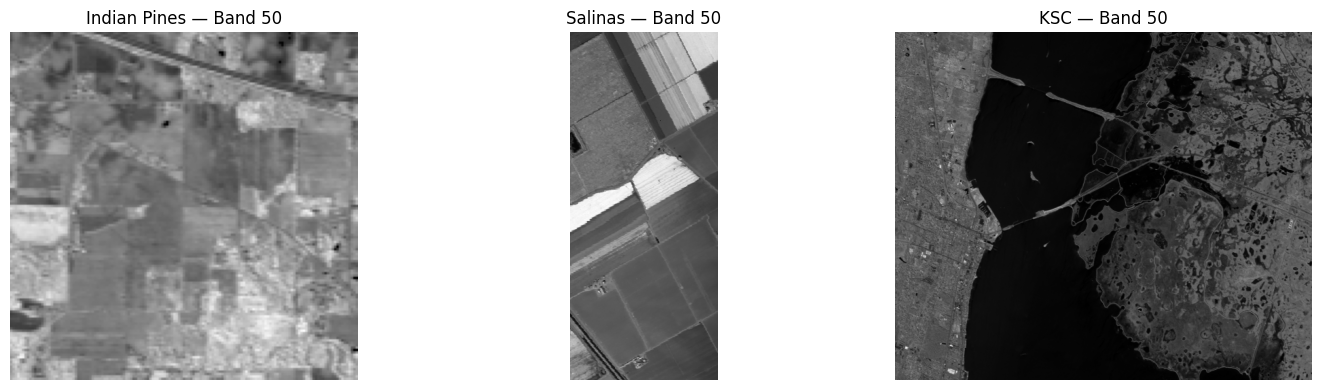

In [7]:
# ## 1.6 Visualize a Single Band (Sanity Check)
#
# We plot band 50 (arbitrary mid-range band) for each dataset
# to visually confirm the data loaded correctly.

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(ip_cube_norm[:, :, 50], cmap='gray')
axes[0].set_title('Indian Pines — Band 50')
axes[0].axis('off')

axes[1].imshow(sa_cube_norm[:, :, 50], cmap='gray')
axes[1].set_title('Salinas — Band 50')
axes[1].axis('off')

axes[2].imshow(ksc_cube_norm[:, :, 50], cmap='gray')
axes[2].set_title('KSC — Band 50')
axes[2].axis('off')

plt.tight_layout()
plt.savefig('band_visualization.png', dpi=150)
plt.show()

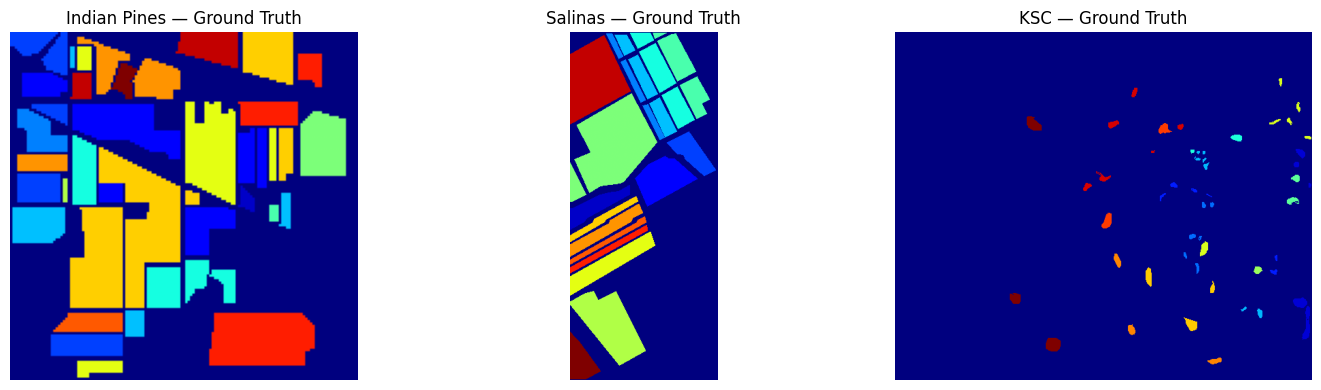

In [8]:
# ## 1.7 Visualize Ground Truth Labels

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(ip_labels, cmap='jet')
axes[0].set_title('Indian Pines — Ground Truth')
axes[0].axis('off')

axes[1].imshow(sa_labels, cmap='jet')
axes[1].set_title('Salinas — Ground Truth')
axes[1].axis('off')

axes[2].imshow(ksc_labels, cmap='jet')
axes[2].set_title('KSC — Ground Truth')
axes[2].axis('off')

plt.tight_layout()
plt.savefig('groundtruth_visualization.png', dpi=150)
plt.show()

In [9]:
# ## 1.8 Train / Test / Validation Split
#
# Following Paper 2 (Medjahed et al. 2016) protocol:
# 10% training / 50% test / 40% validation
# Split is done on labeled pixels only (labels > 0)
# Stratified per class to ensure all classes are represented

from sklearn.model_selection import train_test_split

def split_dataset(labels, train_ratio=0.10, test_ratio=0.50, val_ratio=0.40, seed=42):
    """
    Returns indices for train, test, validation splits.
    Only operates on labeled pixels (label > 0).
    Stratified by class.
    """
    assert abs(train_ratio + test_ratio + val_ratio - 1.0) < 1e-6, "Ratios must sum to 1"
    
    rows, cols = np.where(labels > 0)
    pixel_labels = labels[rows, cols]
    indices = np.stack([rows, cols], axis=1)
    
    # First split: train vs (test + val)
    idx_train, idx_temp, y_train, y_temp = train_test_split(
        indices, pixel_labels,
        test_size=(1 - train_ratio),
        stratify=pixel_labels,
        random_state=seed
    )
    
    # Second split: test vs val from remaining
    val_ratio_adjusted = val_ratio / (test_ratio + val_ratio)
    idx_test, idx_val, y_test, y_val = train_test_split(
        idx_temp, y_temp,
        test_size=val_ratio_adjusted,
        stratify=y_temp,
        random_state=seed
    )
    
    return idx_train, idx_test, idx_val, y_train, y_test, y_val

# Apply to all three datasets
ip_train, ip_test, ip_val, ip_ytrain, ip_ytest, ip_yval = split_dataset(ip_labels)
sa_train, sa_test, sa_val, sa_ytrain, sa_ytest, sa_yval = split_dataset(sa_labels)
ksc_train, ksc_test, ksc_val, ksc_ytrain, ksc_ytest, ksc_yval = split_dataset(ksc_labels)

print("Indian Pines  — Train:", len(ip_train), "| Test:", len(ip_test), "| Val:", len(ip_val))
print("Salinas       — Train:", len(sa_train), "| Test:", len(sa_test), "| Val:", len(sa_val))
print("KSC           — Train:", len(ksc_train), "| Test:", len(ksc_test), "| Val:", len(ksc_val))

Indian Pines  — Train: 1024 | Test: 5125 | Val: 4100
Salinas       — Train: 5412 | Test: 27065 | Val: 21652
KSC           — Train: 521 | Test: 2605 | Val: 2085


In [10]:
# ## 1.9 Save Preprocessed Data
#
# Save normalized cubes and split indices for use in subsequent stages.
# This avoids reloading and reprocessing in every notebook.

np.save('ip_cube_norm.npy',  ip_cube_norm)
np.save('sa_cube_norm.npy',  sa_cube_norm)
np.save('ksc_cube_norm.npy', ksc_cube_norm)

np.save('ip_labels.npy',  ip_labels)
np.save('sa_labels.npy',  sa_labels)
np.save('ksc_labels.npy', ksc_labels)

np.save('ip_train_idx.npy',  ip_train)
np.save('ip_test_idx.npy',   ip_test)
np.save('ip_val_idx.npy',    ip_val)
np.save('ip_ytrain.npy',     ip_ytrain)
np.save('ip_ytest.npy',      ip_ytest)
np.save('ip_yval.npy',       ip_yval)

np.save('sa_train_idx.npy',  sa_train)
np.save('sa_test_idx.npy',   sa_test)
np.save('sa_val_idx.npy',    sa_val)
np.save('sa_ytrain.npy',     sa_ytrain)
np.save('sa_ytest.npy',      sa_ytest)
np.save('sa_yval.npy',       sa_yval)

np.save('ksc_train_idx.npy', ksc_train)
np.save('ksc_test_idx.npy',  ksc_test)
np.save('ksc_val_idx.npy',   ksc_val)
np.save('ksc_ytrain.npy',    ksc_ytrain)
np.save('ksc_ytest.npy',     ksc_ytest)
np.save('ksc_yval.npy',      ksc_yval)

print("All preprocessed data saved successfully")
print("Stage 1 complete — ready for Stage 2 (Band Selection)")

All preprocessed data saved successfully
Stage 1 complete — ready for Stage 2 (Band Selection)


# Stage 2 — Band Selection A: Correlation Grouping + DWT Fusion
# 
# This stage reduces the number of bands by:
# 1. Computing Pearson correlation between all band pairs
# 2. Grouping bands with correlation > 0.98
# 3. Merging each group into one band using DWT averaging
# 4. Applying Secondary Partition (neighborhood-based)
#
# Input  : Normalized HSI cube (H, W, B)
# Output : Reduced HSI cube (H, W, B_reduced)

In [11]:
# ## 2.1 Import Libraries

import numpy as np
import pywt
from scipy.stats import pearsonr
from tqdm import tqdm
import matplotlib.pyplot as plt

print("Libraries loaded successfully")

Libraries loaded successfully


In [12]:
# ## 2.2 Load Preprocessed Data from Stage 1

ip_cube_norm  = np.load('ip_cube_norm.npy')
sa_cube_norm  = np.load('sa_cube_norm.npy')
ksc_cube_norm = np.load('ksc_cube_norm.npy')

ip_labels  = np.load('ip_labels.npy')
sa_labels  = np.load('sa_labels.npy')
ksc_labels = np.load('ksc_labels.npy')

print("Indian Pines  :", ip_cube_norm.shape)
print("Salinas       :", sa_cube_norm.shape)
print("KSC           :", ksc_cube_norm.shape)

Indian Pines  : (145, 145, 200)
Salinas       : (512, 217, 204)
KSC           : (512, 614, 176)


In [13]:
# ## 2.3 Compute Pearson Correlation Matrix
#
# For a cube of B bands, we compute a B x B correlation matrix.
# Entry (i, j) is the Pearson correlation between band i and band j.
# We flatten each band to a 1D vector before computing correlation.
#
# Threshold from Paper 2 (Medjahed 2016): rho > 0.98

def compute_correlation_matrix(cube, threshold=0.98):
    """
    Compute Pearson correlation matrix for all band pairs.
    
    Args:
        cube      : (H, W, B) normalized HSI cube
        threshold : correlation threshold for grouping
    
    Returns:
        corr_matrix : (B, B) correlation matrix
    """
    h, w, b = cube.shape
    # Reshape to (B, H*W) — each band is a row vector
    bands = cube.reshape(-1, b).T  # shape (B, H*W)
    
    corr_matrix = np.corrcoef(bands)  # shape (B, B)
    return corr_matrix

print("Computing correlation matrices...")
ip_corr  = compute_correlation_matrix(ip_cube_norm)
sa_corr  = compute_correlation_matrix(sa_cube_norm)
ksc_corr = compute_correlation_matrix(ksc_cube_norm)

print(f"Indian Pines  correlation matrix: {ip_corr.shape}")
print(f"Salinas       correlation matrix: {sa_corr.shape}")
print(f"KSC           correlation matrix: {ksc_corr.shape}")

Computing correlation matrices...
Indian Pines  correlation matrix: (200, 200)
Salinas       correlation matrix: (204, 204)
KSC           correlation matrix: (176, 176)


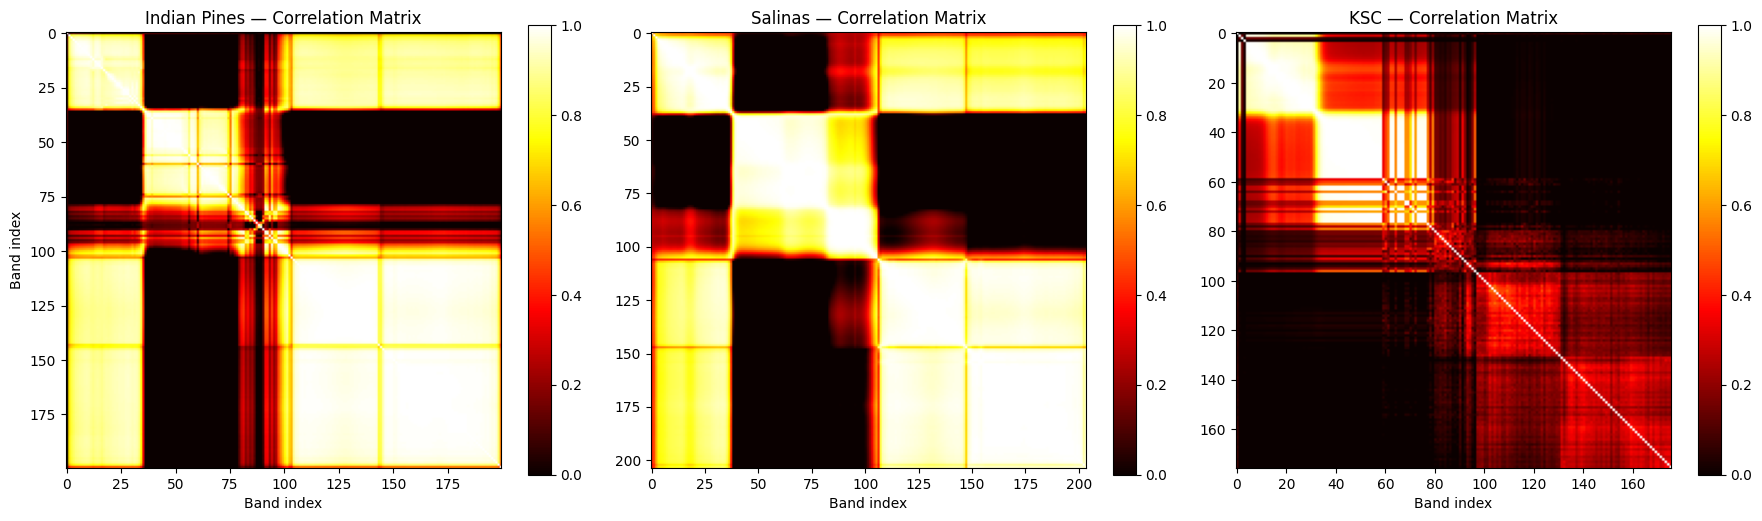

In [14]:
# ## 2.4 Visualize Correlation Matrix (Sanity Check)
#
# A good correlation matrix for HSI data shows block-diagonal structure
# — adjacent bands tend to be highly correlated with each other.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ip_corr, cmap='hot', vmin=0, vmax=1)
axes[0].set_title('Indian Pines — Correlation Matrix')
axes[0].set_xlabel('Band index')
axes[0].set_ylabel('Band index')
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(sa_corr, cmap='hot', vmin=0, vmax=1)
axes[1].set_title('Salinas — Correlation Matrix')
axes[1].set_xlabel('Band index')
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(ksc_corr, cmap='hot', vmin=0, vmax=1)
axes[2].set_title('KSC — Correlation Matrix')
axes[2].set_xlabel('Band index')
plt.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.savefig('correlation_matrices.png', dpi=150)
plt.show()

In [15]:
# ## 2.5 Correlation-Based Band Grouping
#
# We group adjacent bands where correlation > threshold (0.98).
# Algorithm:
#   - Start with band 0 in current group
#   - If next band correlates > 0.98 with ALL bands in current group, add it
#   - Otherwise start a new group
#
# This ensures each group contains only mutually highly-correlated bands.

def group_correlated_bands(corr_matrix, threshold=0.98):
    """
    Group bands based on pairwise correlation threshold.
    
    Args:
        corr_matrix : (B, B) correlation matrix
        threshold   : minimum correlation to group bands together
    
    Returns:
        groups : list of lists, each inner list is a group of band indices
    """
    b = corr_matrix.shape[0]
    visited = [False] * b
    groups = []
    
    for i in range(b):
        if visited[i]:
            continue
        group = [i]
        visited[i] = True
        for j in range(i + 1, b):
            if visited[j]:
                continue
            # Check if band j correlates > threshold with ALL bands in group
            if all(corr_matrix[j, k] > threshold for k in group):
                group.append(j)
                visited[j] = True
        groups.append(group)
    
    return groups

ip_groups  = group_correlated_bands(ip_corr)
sa_groups  = group_correlated_bands(sa_corr)
ksc_groups = group_correlated_bands(ksc_corr)

print(f"Indian Pines  — {len(ip_groups)} groups from {ip_cube_norm.shape[2]} bands")
print(f"Salinas       — {len(sa_groups)} groups from {sa_cube_norm.shape[2]} bands")
print(f"KSC           — {len(ksc_groups)} groups from {ksc_cube_norm.shape[2]} bands")

# Show group size distribution
ip_sizes  = [len(g) for g in ip_groups]
sa_sizes  = [len(g) for g in sa_groups]
ksc_sizes = [len(g) for g in ksc_groups]

print(f"\nIndian Pines  — avg group size: {np.mean(ip_sizes):.2f}, max: {max(ip_sizes)}")
print(f"Salinas       — avg group size: {np.mean(sa_sizes):.2f}, max: {max(sa_sizes)}")
print(f"KSC           — avg group size: {np.mean(ksc_sizes):.2f}, max: {max(ksc_sizes)}")

Indian Pines  — 84 groups from 200 bands
Salinas       — 31 groups from 204 bands
KSC           — 119 groups from 176 bands

Indian Pines  — avg group size: 2.38, max: 39
Salinas       — avg group size: 6.58, max: 51
KSC           — avg group size: 1.48, max: 28


In [16]:
# ## 2.6 DWT Band Fusion
#
# For each group of correlated bands:
#   - If group has only 1 band: keep it as is
#   - If group has multiple bands:
#       * Apply 1-level DWT (db1 wavelet) to each band
#       * Extract approximation coefficients (cA) for each band
#       * Average the approximation coefficients across all bands in group
#       * Reconstruct a single fused band using inverse DWT (idwt)
#
# This gives one representative band per group.

def dwt_band_fusion(cube, groups, wavelet='db1'):
    """
    Fuse each group of correlated bands into one representative band
    using DWT averaging (Paper 2 method).
    
    Args:
        cube    : (H, W, B) normalized HSI cube
        groups  : list of band index groups
        wavelet : wavelet type (db1 = Haar wavelet, simplest)
    
    Returns:
        fused_cube : (H, W, n_groups) reduced cube
    """
    h, w, b = cube.shape
    fused_bands = []
    
    for group in tqdm(groups, desc="Fusing bands"):
        if len(group) == 1:
            # Single band — keep as is
            fused_bands.append(cube[:, :, group[0]])
        else:
            # Multiple bands — fuse via DWT averaging
            ca_list = []
            cd_list = []
            
            for band_idx in group:
                band = cube[:, :, band_idx]  # (H, W)
                # Apply DWT row-wise then column-wise (2D DWT approximation)
                # We use 1D DWT along rows and average
                ca_rows = []
                for row in range(h):
                    ca, cd = pywt.dwt(band[row, :], wavelet)
                    ca_rows.append(ca)
                ca_list.append(np.array(ca_rows))  # (H, W//2+1)
            
            # Average approximation coefficients across all bands in group
            ca_avg = np.mean(np.stack(ca_list, axis=0), axis=0)  # (H, W//2+1)
            
            # Reconstruct band using inverse DWT
            # Use cd from last band as detail (or zeros)
            cd_last = []
            band_last = cube[:, :, group[-1]]
            for row in range(h):
                ca, cd = pywt.dwt(band_last[row, :], wavelet)
                cd_last.append(cd)
            cd_last = np.array(cd_last)
            
            # Reconstruct each row
            reconstructed = []
            for row in range(h):
                rec = pywt.idwt(ca_avg[row], cd_last[row], wavelet)
                reconstructed.append(rec[:w])  # crop to original width
            
            fused_band = np.array(reconstructed)  # (H, W)
            fused_bands.append(fused_band)
    
    fused_cube = np.stack(fused_bands, axis=-1)  # (H, W, n_groups)
    return fused_cube

print("Applying DWT band fusion...")
ip_fused  = dwt_band_fusion(ip_cube_norm,  ip_groups)
sa_fused  = dwt_band_fusion(sa_cube_norm,  sa_groups)
ksc_fused = dwt_band_fusion(ksc_cube_norm, ksc_groups)

print(f"\nIndian Pines  — {ip_cube_norm.shape[2]} bands → {ip_fused.shape[2]} bands")
print(f"Salinas       — {sa_cube_norm.shape[2]} bands → {sa_fused.shape[2]} bands")
print(f"KSC           — {ksc_cube_norm.shape[2]} bands → {ksc_fused.shape[2]} bands")

Applying DWT band fusion...


Fusing bands: 100%|██████████| 119/119 [00:00<00:00, 219.06it/s]



Indian Pines  — 200 bands → 84 bands
Salinas       — 204 bands → 31 bands
KSC           — 176 bands → 119 bands


In [17]:
# ## 2.7 Secondary Partition — Neighborhood-Based
#
# From Paper 1 (Kumar et al. 2024):
# Within each group, generate a weight matrix quantifying
# how each pixel relates to its spatial neighbors.
# This preserves local spatial structure within each partition.
#
# Implementation:
#   For each fused band, compute a spatially-weighted version
#   using an 8-connected neighborhood average.
#   Weight matrix W(i,j) = 1 / (1 + ||pixel_i - pixel_j||)

def neighborhood_partition(fused_cube):
    """
    Apply neighborhood partition to each band of fused cube.
    Uses 8-connected spatial neighborhood weighting.
    
    Args:
        fused_cube : (H, W, B) fused band cube
    
    Returns:
        partitioned_cube : (H, W, B) spatially weighted cube
    """
    from scipy.ndimage import uniform_filter
    
    h, w, b = fused_cube.shape
    partitioned = np.zeros_like(fused_cube)
    
    for i in range(b):
        band = fused_cube[:, :, i]
        # 8-connected neighborhood average (3x3 window)
        neighbor_avg = uniform_filter(band, size=3)
        # Weight: blend original with neighborhood
        # alpha controls how much spatial context is added
        alpha = 0.5
        partitioned[:, :, i] = alpha * band + (1 - alpha) * neighbor_avg
    
    return partitioned

print("Applying neighborhood partition...")
ip_partitioned  = neighborhood_partition(ip_fused)
sa_partitioned  = neighborhood_partition(sa_fused)
ksc_partitioned = neighborhood_partition(ksc_fused)

print(f"Indian Pines  — partitioned cube shape: {ip_partitioned.shape}")
print(f"Salinas       — partitioned cube shape: {sa_partitioned.shape}")
print(f"KSC           — partitioned cube shape: {ksc_partitioned.shape}")

Applying neighborhood partition...
Indian Pines  — partitioned cube shape: (145, 145, 84)
Salinas       — partitioned cube shape: (512, 217, 31)
KSC           — partitioned cube shape: (512, 614, 119)


In [18]:
# ## 2.8 Save Stage 2 Output

np.save('ip_stage2.npy',  ip_partitioned)
np.save('sa_stage2.npy',  sa_partitioned)
np.save('ksc_stage2.npy', ksc_partitioned)

# Also save group information for reference in report
np.save('ip_groups.npy',  np.array(ip_groups,  dtype=object), allow_pickle=True)
np.save('sa_groups.npy',  np.array(sa_groups,  dtype=object), allow_pickle=True)
np.save('ksc_groups.npy', np.array(ksc_groups, dtype=object), allow_pickle=True)

print("Stage 2 outputs saved")
print(f"\nBand reduction summary:")
print(f"  Indian Pines  : 200 → {ip_partitioned.shape[2]} bands")
print(f"  Salinas       : 204 → {sa_partitioned.shape[2]} bands")
print(f"  KSC           : 176 → {ksc_partitioned.shape[2]} bands")
print("\nStage 2 complete — ready for Stage 3 (Wavelet Entropy + JM Filtering)")

Stage 2 outputs saved

Band reduction summary:
  Indian Pines  : 200 → 84 bands
  Salinas       : 204 → 31 bands
  KSC           : 176 → 119 bands

Stage 2 complete — ready for Stage 3 (Wavelet Entropy + JM Filtering)


# Stage 3 — Band Ranking: Wavelet Entropy + JM Distance Filtering
#
# This stage selects the most informative AND class-discriminative bands.
#
# Step 1: Wavelet Entropy Ranking (Paper 1)
#         — rank bands by information content
# Step 2: JM Distance Filtering (Paper 2 — our addition)
#         — remove bands with poor class separability
#
# Input  : Stage 2 partitioned cube (H, W, B_reduced)
# Output : Final selected band cube (H, W, p) where p << B_reduced

In [19]:
# ## 3.1 Import Libraries

import numpy as np
import pywt
import matplotlib.pyplot as plt
from tqdm import tqdm

print("Libraries loaded successfully")

Libraries loaded successfully


In [20]:
# ## 3.2 Load Stage 2 Outputs

ip_cube  = np.load('ip_stage2.npy')
sa_cube  = np.load('sa_stage2.npy')
ksc_cube = np.load('ksc_stage2.npy')

ip_labels  = np.load('ip_labels.npy')
sa_labels  = np.load('sa_labels.npy')
ksc_labels = np.load('ksc_labels.npy')

print(f"Indian Pines  : {ip_cube.shape}")
print(f"Salinas       : {sa_cube.shape}")
print(f"KSC           : {ksc_cube.shape}")

Indian Pines  : (145, 145, 84)
Salinas       : (512, 217, 31)
KSC           : (512, 614, 119)


In [21]:
# ## 3.3 Wavelet Entropy Computation
#
# For each band b:
#   1. Apply multilevel DWT decomposition (level=3)
#   2. Compute energy at each decomposition level j:
#      E_j = sum of squared wavelet coefficients at level j
#   3. Total energy: E_tot = sum of all E_j
#   4. Relative energy: P_j = E_j / E_tot
#   5. Wavelet entropy: S_wt = -sum(P_j * log(P_j))
#
# Higher entropy = more information = higher rank

def wavelet_entropy(band, wavelet='db1', level=3):
    """
    Compute wavelet entropy of a 2D band.
    
    Args:
        band    : (H, W) 2D array
        wavelet : wavelet type
        level   : decomposition level
    
    Returns:
        entropy : scalar wavelet entropy value
    """
    # Flatten band to 1D for wavelet decomposition
    signal = band.flatten()
    
    # Multilevel DWT decomposition
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    
    # Compute energy at each level
    energies = np.array([np.sum(c**2) for c in coeffs])
    total_energy = np.sum(energies)
    
    if total_energy == 0:
        return 0.0
    
    # Relative energy (probability distribution)
    P = energies / total_energy
    
    # Remove zeros to avoid log(0)
    P = P[P > 0]
    
    # Wavelet entropy
    entropy = -np.sum(P * np.log(P))
    return entropy


def compute_wavelet_entropy_all_bands(cube):
    """
    Compute wavelet entropy for every band in the cube.
    
    Args:
        cube : (H, W, B) HSI cube
    
    Returns:
        entropies : (B,) array of entropy values
    """
    b = cube.shape[2]
    entropies = np.zeros(b)
    for i in tqdm(range(b), desc="Computing wavelet entropy"):
        entropies[i] = wavelet_entropy(cube[:, :, i])
    return entropies

print("Computing wavelet entropies...")
ip_entropies  = compute_wavelet_entropy_all_bands(ip_cube)
sa_entropies  = compute_wavelet_entropy_all_bands(sa_cube)
ksc_entropies = compute_wavelet_entropy_all_bands(ksc_cube)

print(f"\nIndian Pines  — entropy range: [{ip_entropies.min():.4f}, {ip_entropies.max():.4f}]")
print(f"Salinas       — entropy range: [{sa_entropies.min():.4f}, {sa_entropies.max():.4f}]")
print(f"KSC           — entropy range: [{ksc_entropies.min():.4f}, {ksc_entropies.max():.4f}]")

Computing wavelet entropies...


Computing wavelet entropy: 100%|██████████| 119/119 [00:00<00:00, 302.85it/s]


Indian Pines  — entropy range: [0.0315, 0.5879]
Salinas       — entropy range: [0.0174, 0.1417]
KSC           — entropy range: [0.1454, 1.3659]


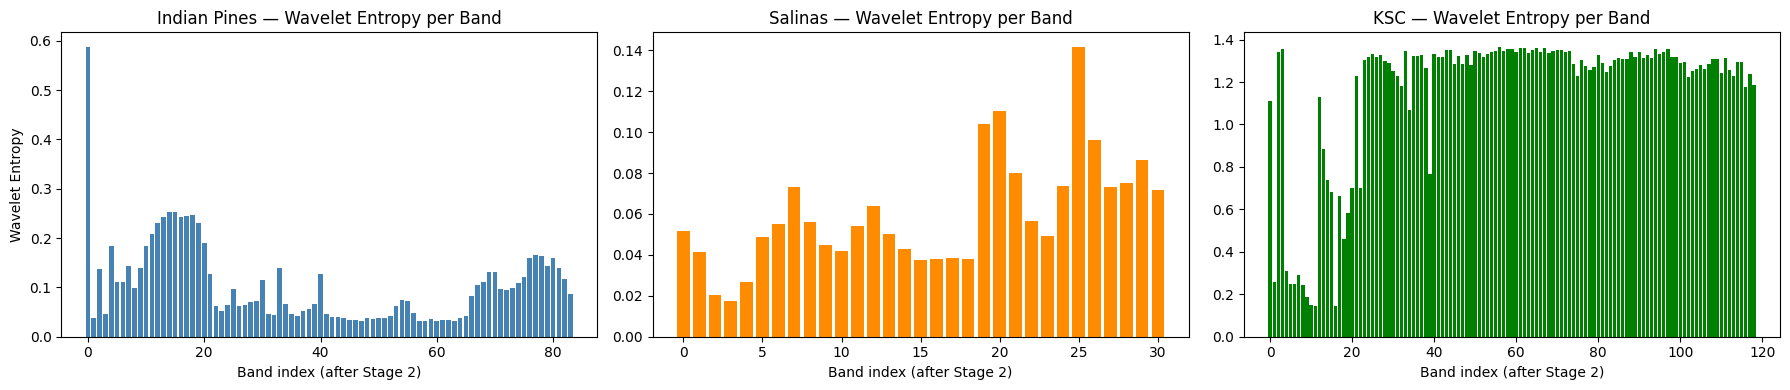

In [22]:
# ## 3.4 Visualize Wavelet Entropy Distribution

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].bar(range(len(ip_entropies)), ip_entropies, color='steelblue')
axes[0].set_title('Indian Pines — Wavelet Entropy per Band')
axes[0].set_xlabel('Band index (after Stage 2)')
axes[0].set_ylabel('Wavelet Entropy')

axes[1].bar(range(len(sa_entropies)), sa_entropies, color='darkorange')
axes[1].set_title('Salinas — Wavelet Entropy per Band')
axes[1].set_xlabel('Band index (after Stage 2)')

axes[2].bar(range(len(ksc_entropies)), ksc_entropies, color='green')
axes[2].set_title('KSC — Wavelet Entropy per Band')
axes[2].set_xlabel('Band index (after Stage 2)')

plt.tight_layout()
plt.savefig('wavelet_entropy.png', dpi=150)
plt.show()

In [23]:
# ## 3.5 Select Top-N Bands by Wavelet Entropy
#
# We select the top N bands with highest entropy.
# N is set to 30 as a starting point (can be tuned).
# This matches the target of 10-20 bands mentioned in the proposal
# before JM filtering further reduces it.

def select_top_n_bands(cube, entropies, n=30):
    """
    Select top-n bands ranked by wavelet entropy.
    
    Args:
        cube      : (H, W, B) HSI cube
        entropies : (B,) entropy values
        n         : number of bands to select
    
    Returns:
        selected_cube    : (H, W, n) reduced cube
        selected_indices : (n,) indices of selected bands
    """
    n = min(n, len(entropies))
    top_indices = np.argsort(entropies)[::-1][:n]
    top_indices_sorted = np.sort(top_indices)  # keep spectral order
    selected_cube = cube[:, :, top_indices_sorted]
    return selected_cube, top_indices_sorted

N_BANDS = 30

ip_entropy_selected,  ip_entropy_idx  = select_top_n_bands(ip_cube,  ip_entropies,  N_BANDS)
sa_entropy_selected,  sa_entropy_idx  = select_top_n_bands(sa_cube,  sa_entropies,  N_BANDS)
ksc_entropy_selected, ksc_entropy_idx = select_top_n_bands(ksc_cube, ksc_entropies, N_BANDS)

print(f"After entropy ranking (top {N_BANDS}):")
print(f"  Indian Pines  : {ip_cube.shape[2]} → {ip_entropy_selected.shape[2]} bands")
print(f"  Salinas       : {sa_cube.shape[2]} → {sa_entropy_selected.shape[2]} bands")
print(f"  KSC           : {ksc_cube.shape[2]} → {ksc_entropy_selected.shape[2]} bands")

After entropy ranking (top 30):
  Indian Pines  : 84 → 30 bands
  Salinas       : 31 → 30 bands
  KSC           : 119 → 30 bands


In [24]:
# ## 3.6 — JM Filtering with NaN handling

def jm_filter_bands(cube, labels, percentile=25):
    """
    Filter bands by JM distance threshold.
    Handles NaN scores by replacing with 0.
    Keeps bands above the given percentile of valid JM scores.
    """
    h, w, b = cube.shape
    labels_flat = labels.flatten()
    jm_scores = np.zeros(b)
    
    for i in tqdm(range(b), desc="Computing JM distances"):
        band_flat = cube[:, :, i].flatten()
        mask = labels_flat > 0
        score = compute_mean_jm_distance(
            band_flat[mask], labels_flat[mask]
        )
        # Replace NaN with 0 — NaN bands are uninformative
        jm_scores[i] = 0.0 if np.isnan(score) else score
    
    # Compute threshold only from valid (non-zero) scores
    valid_scores = jm_scores[jm_scores > 0]
    threshold = np.percentile(valid_scores, percentile)
    
    selected_indices = np.where(jm_scores >= threshold)[0]
    filtered_cube = cube[:, :, selected_indices]
    
    return filtered_cube, selected_indices, jm_scores

print("Applying JM distance filtering...")
ip_final,  ip_jm_idx,  ip_jm_scores  = jm_filter_bands(ip_entropy_selected,  ip_labels)
sa_final,  sa_jm_idx,  sa_jm_scores  = jm_filter_bands(sa_entropy_selected,  sa_labels)
ksc_final, ksc_jm_idx, ksc_jm_scores = jm_filter_bands(ksc_entropy_selected, ksc_labels)

print(f"\nAfter JM filtering:")
print(f"  Indian Pines  : {ip_entropy_selected.shape[2]} → {ip_final.shape[2]} bands")
print(f"  Salinas       : {sa_entropy_selected.shape[2]} → {sa_final.shape[2]} bands")
print(f"  KSC           : {ksc_entropy_selected.shape[2]} → {ksc_final.shape[2]} bands")

Applying JM distance filtering...


Computing JM distances:   0%|          | 0/30 [00:00<?, ?it/s]/tmp/ipykernel_50/813501826.py:174: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(2 * (1 - np.exp(-B)))
Computing JM distances: 100%|██████████| 30/30 [00:00<00:00, 138.46it/s]


After JM filtering:
  Indian Pines  : 30 → 22 bands
  Salinas       : 30 → 22 bands
  KSC           : 30 → 19 bands


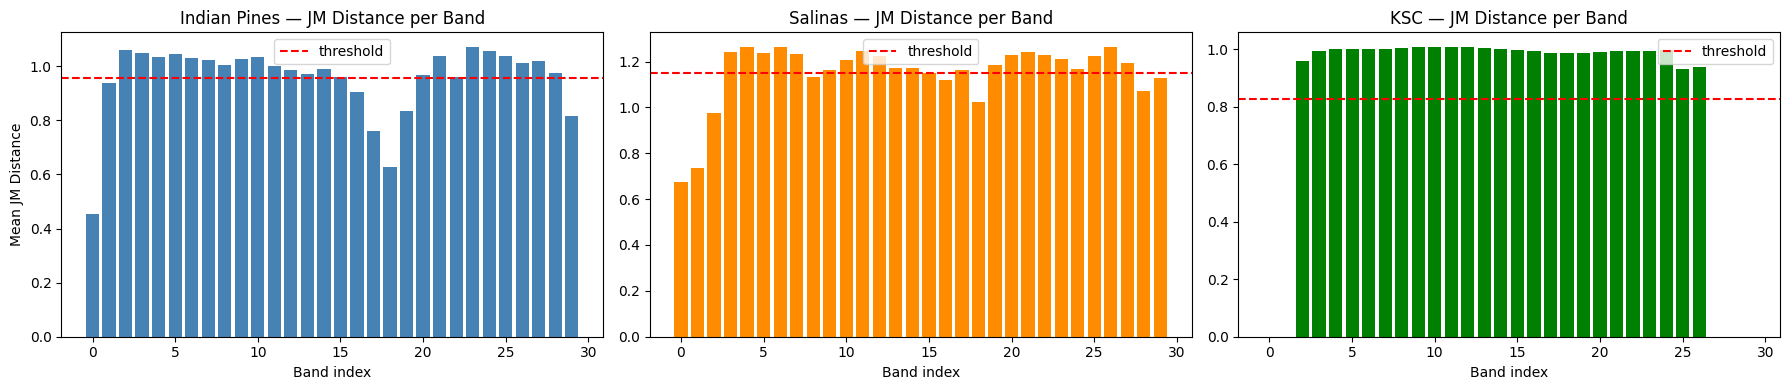

In [25]:
# ## 3.7 Visualize JM Distance Scores

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].bar(range(len(ip_jm_scores)), ip_jm_scores, color='steelblue')
axes[0].axhline(np.mean(ip_jm_scores), color='red', 
                linestyle='--', label='threshold')
axes[0].set_title('Indian Pines — JM Distance per Band')
axes[0].set_xlabel('Band index')
axes[0].set_ylabel('Mean JM Distance')
axes[0].legend()

axes[1].bar(range(len(sa_jm_scores)), sa_jm_scores, color='darkorange')
axes[1].axhline(np.mean(sa_jm_scores), color='red',
                linestyle='--', label='threshold')
axes[1].set_title('Salinas — JM Distance per Band')
axes[1].set_xlabel('Band index')
axes[1].legend()

axes[2].bar(range(len(ksc_jm_scores)), ksc_jm_scores, color='green')
axes[2].axhline(np.mean(ksc_jm_scores), color='red',
                linestyle='--', label='threshold')
axes[2].set_title('KSC — JM Distance per Band')
axes[2].set_xlabel('Band index')
axes[2].legend()

plt.tight_layout()
plt.savefig('jm_distances.png', dpi=150)
plt.show()

In [26]:
# ## 3.8 Full Band Reduction Summary

print("=" * 55)
print("Band Reduction Summary Across All Stages")
print("=" * 55)
print(f"{'Dataset':<15} {'Original':>10} {'Stage2':>10} {'Stage3':>10}")
print("-" * 55)
print(f"{'Indian Pines':<15} {200:>10} {ip_cube.shape[2]:>10} {ip_final.shape[2]:>10}")
print(f"{'Salinas':<15} {204:>10} {sa_cube.shape[2]:>10} {sa_final.shape[2]:>10}")
print(f"{'KSC':<15} {176:>10} {ksc_cube.shape[2]:>10} {ksc_final.shape[2]:>10}")
print("=" * 55)

Band Reduction Summary Across All Stages
Dataset           Original     Stage2     Stage3
-------------------------------------------------------
Indian Pines           200         84         22
Salinas                204         31         22
KSC                    176        119         19


In [27]:
# ## 3.9 Save Stage 3 Outputs

np.save('ip_stage3.npy',  ip_final)
np.save('sa_stage3.npy',  sa_final)
np.save('ksc_stage3.npy', ksc_final)

np.save('ip_jm_scores.npy',  ip_jm_scores)
np.save('sa_jm_scores.npy',  sa_jm_scores)
np.save('ksc_jm_scores.npy', ksc_jm_scores)

print("Stage 3 outputs saved")
print("\nStage 3 complete — ready for Stage 4 (Hemispherical Reflectance Filtering)")

Stage 3 outputs saved

Stage 3 complete — ready for Stage 4 (Hemispherical Reflectance Filtering)


# Stage 4 — Hemispherical Reflectance Spatial Filtering
#
# This stage applies spatial filtering to the band-selected cube.
# Unlike simple smoothing, this filter weights neighbors by spectral
# similarity — preserving boundaries while smoothing homogeneous regions.
#
# Based on Paper 1 (Kumar et al. 2024):
#   - Bi-hemispherical reflectance is an intrinsic surface property
#   - Uses first-order IIR filter with feedback parameter r ∈ [0, 1]
#   - Preserves pixel-to-pixel distances via isometric transformation
#
# Input  : Stage 3 selected band cube (H, W, p)
# Output : Spatially filtered cube (H, W, p)

In [28]:
# ## 4.1 Import Libraries

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

print("Libraries loaded successfully")

Libraries loaded successfully


In [29]:
# ## 4.2 Load Stage 3 Outputs

ip_cube  = np.load('ip_stage3.npy')
sa_cube  = np.load('sa_stage3.npy')
ksc_cube = np.load('ksc_stage3.npy')

ip_labels  = np.load('ip_labels.npy')
sa_labels  = np.load('sa_labels.npy')
ksc_labels = np.load('ksc_labels.npy')

print(f"Indian Pines  : {ip_cube.shape}")
print(f"Salinas       : {sa_cube.shape}")
print(f"KSC           : {ksc_cube.shape}")

Indian Pines  : (145, 145, 22)
Salinas       : (512, 217, 22)
KSC           : (512, 614, 19)


In [30]:
# ## 4.3 Spectral Similarity Weight Computation
#
# For each pixel and its 8 connected neighbors:
#   weight(i,j) = exp(-||s_i - s_j||^2 / (2 * sigma^2))
#
# where s_i and s_j are spectral vectors of pixels i and j.
# sigma controls sensitivity to spectral differences.
# High weight = spectrally similar = smooth across boundary
# Low weight  = spectrally different = preserve boundary

def compute_spectral_weights(cube, sigma=0.1):
    """
    Compute spectral similarity weights for 8-connected neighbors.
    
    Args:
        cube  : (H, W, B) HSI cube
        sigma : bandwidth parameter for similarity kernel
    
    Returns:
        weights : (H, W, 8) weight array for 8 neighbors
                  neighbor order: NW N NE W E SW S SE
    """
    h, w, b = cube.shape
    weights = np.zeros((h, w, 8))
    
    # 8-connected neighbor offsets (row, col)
    # Order: NW, N, NE, W, E, SW, S, SE
    offsets = [
        (-1, -1), (-1, 0), (-1, 1),
        ( 0, -1),           (0,  1),
        ( 1, -1), ( 1, 0), ( 1,  1)
    ]
    
    for k, (dr, dc) in enumerate(offsets):
        for i in range(h):
            for j in range(w):
                ni, nj = i + dr, j + dc
                # Check boundary
                if 0 <= ni < h and 0 <= nj < w:
                    # Spectral vectors
                    s_center   = cube[i,  j,  :]
                    s_neighbor = cube[ni, nj, :]
                    # Squared Euclidean distance
                    dist_sq = np.sum((s_center - s_neighbor) ** 2)
                    # Gaussian similarity weight
                    weights[i, j, k] = np.exp(-dist_sq / (2 * sigma**2))
                else:
                    weights[i, j, k] = 0.0  # out of bounds
    
    return weights

In [31]:
# ## 4.4 Hemispherical Reflectance IIR Filter
#
# First-order IIR filter with feedback parameter r:
#   H_filtered(i,j) = (1-r) * H(i,j) + r * sum(w_k * H(neighbor_k)) / sum(w_k)
#
# r ∈ [0, 1]:
#   r = 0 → no filtering (original)
#   r = 1 → full neighborhood average
#   r = 0.5 → balanced (recommended starting point)
#
# The spectral weights ensure:
#   - Similar neighbors contribute more → smooth homogeneous regions
#   - Dissimilar neighbors contribute less → preserve boundaries

def hemispherical_reflectance_filter(cube, r=0.5, sigma=0.1):
    """
    Apply hemispherical reflectance spatial filter.
    
    Args:
        cube  : (H, W, B) HSI cube
        r     : IIR feedback parameter ∈ [0, 1]
        sigma : spectral similarity bandwidth
    
    Returns:
        filtered_cube : (H, W, B) spatially filtered cube
    """
    h, w, b = cube.shape
    
    # 8-connected neighbor offsets
    offsets = [
        (-1, -1), (-1, 0), (-1, 1),
        ( 0, -1),           (0,  1),
        ( 1, -1), ( 1, 0), ( 1,  1)
    ]
    
    filtered_cube = np.zeros_like(cube)
    
    for band_idx in tqdm(range(b), desc="Filtering bands"):
        band = cube[:, :, band_idx]
        filtered_band = np.zeros_like(band)
        
        for i in range(h):
            for j in range(w):
                s_center = cube[i, j, :]  # full spectral vector for weights
                
                weighted_sum = 0.0
                weight_total = 0.0
                
                for dr, dc in offsets:
                    ni, nj = i + dr, j + dc
                    if 0 <= ni < h and 0 <= nj < w:
                        s_neighbor = cube[ni, nj, :]
                        dist_sq = np.sum((s_center - s_neighbor)**2)
                        w_k = np.exp(-dist_sq / (2 * sigma**2))
                        weighted_sum += w_k * band[ni, nj]
                        weight_total += w_k
                
                if weight_total > 0:
                    neighbor_avg = weighted_sum / weight_total
                else:
                    neighbor_avg = band[i, j]
                
                # IIR filter equation
                filtered_band[i, j] = (1 - r) * band[i, j] + r * neighbor_avg
        
        filtered_cube[:, :, band_idx] = filtered_band
    
    return filtered_cube

In [32]:
# ## 4.5 Apply Filter to All Datasets
#
# r = 0.5 : balanced boundary preservation vs smoothing
# sigma = 0.1 : moderate spectral similarity sensitivity
#
# Note: This is pixel-by-pixel so it takes a few minutes.
# KSC is largest (512x614) so will take longest.

R     = 0.5
SIGMA = 0.1

print(f"Applying hemispherical reflectance filter (r={R}, sigma={SIGMA})...")
print("\nProcessing Indian Pines...")
ip_filtered  = hemispherical_reflectance_filter(ip_cube,  r=R, sigma=SIGMA)

print("\nProcessing Salinas...")
sa_filtered  = hemispherical_reflectance_filter(sa_cube,  r=R, sigma=SIGMA)

print("\nProcessing KSC...")
ksc_filtered = hemispherical_reflectance_filter(ksc_cube, r=R, sigma=SIGMA)

print("\nFiltering complete")
print(f"Indian Pines  : {ip_filtered.shape}")
print(f"Salinas       : {sa_filtered.shape}")
print(f"KSC           : {ksc_filtered.shape}")

Applying hemispherical reflectance filter (r=0.5, sigma=0.1)...

Processing Indian Pines...


Filtering bands: 100%|██████████| 22/22 [00:26<00:00,  1.22s/it]



Processing Salinas...


Filtering bands: 100%|██████████| 22/22 [02:23<00:00,  6.51s/it]



Processing KSC...


Filtering bands: 100%|██████████| 19/19 [05:54<00:00, 18.67s/it]


Filtering complete
Indian Pines  : (145, 145, 22)
Salinas       : (512, 217, 22)
KSC           : (512, 614, 19)


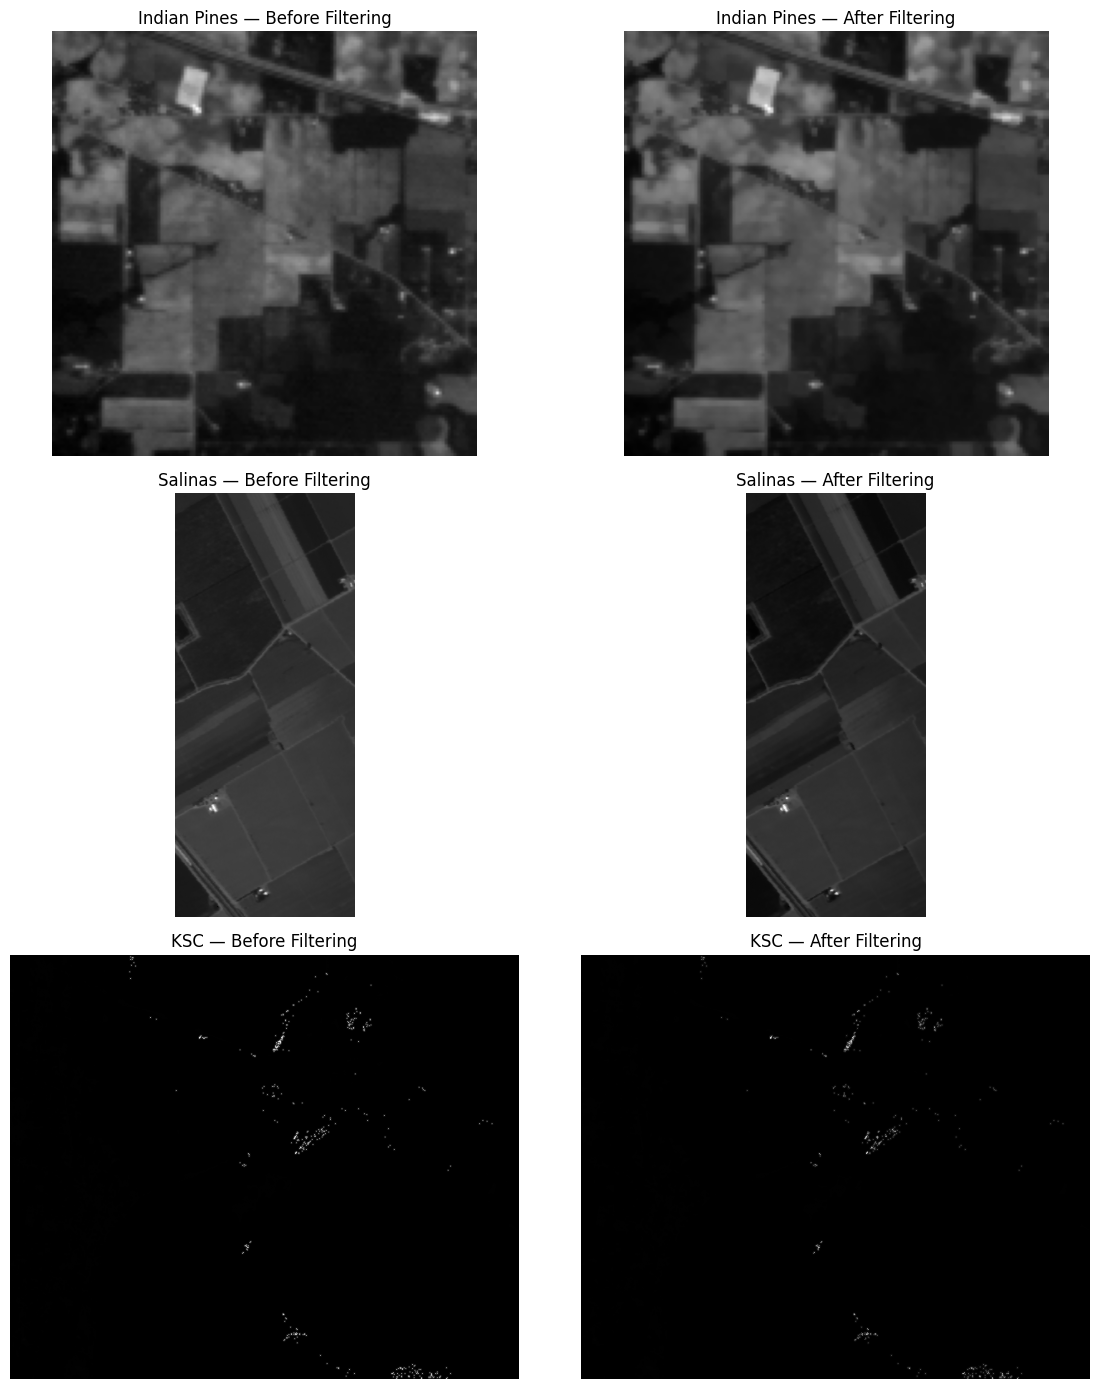

In [33]:
# ## 4.6 Visualize Filtering Effect
#
# Compare band 0 before and after filtering for each dataset.
# Good filtering should show:
#   - Smoother homogeneous regions
#   - Sharp boundaries preserved

fig, axes = plt.subplots(3, 2, figsize=(12, 14))

# Indian Pines
axes[0, 0].imshow(ip_cube[:, :, 0], cmap='gray')
axes[0, 0].set_title('Indian Pines — Before Filtering')
axes[0, 0].axis('off')
axes[0, 1].imshow(ip_filtered[:, :, 0], cmap='gray')
axes[0, 1].set_title('Indian Pines — After Filtering')
axes[0, 1].axis('off')

# Salinas
axes[1, 0].imshow(sa_cube[:, :, 0], cmap='gray')
axes[1, 0].set_title('Salinas — Before Filtering')
axes[1, 0].axis('off')
axes[1, 1].imshow(sa_filtered[:, :, 0], cmap='gray')
axes[1, 1].set_title('Salinas — After Filtering')
axes[1, 1].axis('off')

# KSC
axes[2, 0].imshow(ksc_cube[:, :, 0], cmap='gray')
axes[2, 0].set_title('KSC — Before Filtering')
axes[2, 0].axis('off')
axes[2, 1].imshow(ksc_filtered[:, :, 0], cmap='gray')
axes[2, 1].set_title('KSC — After Filtering')
axes[2, 1].axis('off')

plt.tight_layout()
plt.savefig('filtering_comparison.png', dpi=150)
plt.show()

In [34]:
# ## 4.7 Quantitative Check
#
# Verify filtering did not destroy information:
#   - Mean should be similar before and after
#   - Std should decrease slightly (smoothing effect)
#   - Min/max should stay in [0, 1] range

print("Quantitative filtering check:")
print(f"\nIndian Pines:")
print(f"  Before — mean: {ip_cube.mean():.4f}, std: {ip_cube.std():.4f}")
print(f"  After  — mean: {ip_filtered.mean():.4f}, std: {ip_filtered.std():.4f}")

print(f"\nSalinas:")
print(f"  Before — mean: {sa_cube.mean():.4f}, std: {sa_cube.std():.4f}")
print(f"  After  — mean: {sa_filtered.mean():.4f}, std: {sa_filtered.std():.4f}")

print(f"\nKSC:")
print(f"  Before — mean: {ksc_cube.mean():.4f}, std: {ksc_cube.std():.4f}")
print(f"  After  — mean: {ksc_filtered.mean():.4f}, std: {ksc_filtered.std():.4f}")

Quantitative filtering check:

Indian Pines:
  Before — mean: 0.2824, std: 0.1776
  After  — mean: 0.2823, std: 0.1772

Salinas:
  Before — mean: 0.2461, std: 0.1748
  After  — mean: 0.2461, std: 0.1747

KSC:
  Before — mean: 0.0024, std: 0.0191
  After  — mean: 0.0023, std: 0.0157


In [35]:
# ## 4.8 Save Stage 4 Outputs

np.save('ip_stage4.npy',  ip_filtered)
np.save('sa_stage4.npy',  sa_filtered)
np.save('ksc_stage4.npy', ksc_filtered)

print("Stage 4 outputs saved")
print("\nStage 4 complete — ready for Stage 5 (Classification + CEC)")

Stage 4 outputs saved

Stage 4 complete — ready for Stage 5 (Classification + CEC)


# Stage 5 — Classification and CEC Error Correction
#
# Part A: Classification
#   - Baseline : SVM (Gaussian kernel, C=2, sigma=0.01)
#   - Advanced : 3D-CNN (Conv → Pool → Fully Connected)
#
# Part B: CEC Post-classification
#   - 8-connected neighbor examination
#   - 4 transition rules
#   - Spectral Angle Mapper tie-breaking
#
# Input  : Stage 4 filtered cube (H, W, p)
# Output : Classification maps + OA/AA/Kappa metrics

In [36]:
# ## 0. Rebuild all previous stages before Stage 5
# Run this once after session restart to regenerate all .npy files

import numpy as np
import scipy.io as sio
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
import pywt
from scipy.ndimage import uniform_filter
from tqdm import tqdm

# ── Stage 1 ──────────────────────────────────────────────
ip_data  = sio.loadmat('/kaggle/input/datasets/freeman2147/1992-indian-pines/Indian_pines_corrected.mat')
ip_gt    = sio.loadmat('/kaggle/input/datasets/freeman2147/1992-indian-pines/Indian_pines_gt.mat')
sa_data  = sio.loadmat('/kaggle/input/datasets/wangyijialili/salinas/salinas_corrected.mat')
sa_gt    = sio.loadmat('/kaggle/input/datasets/wangyijialili/salinas/salinas_gt.mat')
ksc_data = sio.loadmat('/kaggle/input/datasets/sreevallimanda/ksc-hyperspectral/KSC.mat')
ksc_gt   = sio.loadmat('/kaggle/input/datasets/sreevallimanda/ksc-hyperspectral/KSC_gt.mat')

ip_cube   = ip_data['indian_pines_corrected']
ip_labels = ip_gt['indian_pines_gt']
sa_cube   = sa_data['salinas_corrected']
sa_labels = sa_gt['salinas_gt']
ksc_cube  = ksc_data['KSC']
ksc_labels = ksc_gt['KSC_gt']

def normalize_cube(cube):
    h, w, b = cube.shape
    cube_reshaped = cube.reshape(-1, b).astype(np.float32)
    scaler = MinMaxScaler()
    return scaler.fit_transform(cube_reshaped).reshape(h, w, b)

ip_cube_norm  = normalize_cube(ip_cube)
sa_cube_norm  = normalize_cube(sa_cube)
ksc_cube_norm = normalize_cube(ksc_cube)

def split_dataset(labels, train_ratio=0.10, test_ratio=0.50,
                  val_ratio=0.40, seed=42):
    rows, cols = np.where(labels > 0)
    pixel_labels = labels[rows, cols]
    indices = np.stack([rows, cols], axis=1)
    idx_train, idx_temp, y_train, y_temp = train_test_split(
        indices, pixel_labels,
        test_size=(1 - train_ratio),
        stratify=pixel_labels, random_state=seed)
    val_ratio_adj = val_ratio / (test_ratio + val_ratio)
    idx_test, idx_val, y_test, y_val = train_test_split(
        idx_temp, y_temp,
        test_size=val_ratio_adj,
        stratify=y_temp, random_state=seed)
    return idx_train, idx_test, idx_val, y_train, y_test, y_val

ip_train_idx,  ip_test_idx,  ip_val_idx,  ip_ytrain,  ip_ytest,  ip_yval  = split_dataset(ip_labels)
sa_train_idx,  sa_test_idx,  sa_val_idx,  sa_ytrain,  sa_ytest,  sa_yval  = split_dataset(sa_labels)
ksc_train_idx, ksc_test_idx, ksc_val_idx, ksc_ytrain, ksc_ytest, ksc_yval = split_dataset(ksc_labels)

print("Stage 1 done")

# ── Stage 2 ──────────────────────────────────────────────
def compute_correlation_matrix(cube):
    h, w, b = cube.shape
    bands = cube.reshape(-1, b).T
    return np.corrcoef(bands)

def group_correlated_bands(corr_matrix, threshold=0.98):
    b = corr_matrix.shape[0]
    visited = [False] * b
    groups = []
    for i in range(b):
        if visited[i]:
            continue
        group = [i]
        visited[i] = True
        for j in range(i + 1, b):
            if visited[j]:
                continue
            if all(corr_matrix[j, k] > threshold for k in group):
                group.append(j)
                visited[j] = True
        groups.append(group)
    return groups

def dwt_band_fusion(cube, groups, wavelet='db1'):
    h, w, b = cube.shape
    fused_bands = []
    for group in groups:
        if len(group) == 1:
            fused_bands.append(cube[:, :, group[0]])
        else:
            ca_list = []
            for band_idx in group:
                band = cube[:, :, band_idx]
                ca_rows = []
                for row in range(h):
                    ca, cd = pywt.dwt(band[row, :], wavelet)
                    ca_rows.append(ca)
                ca_list.append(np.array(ca_rows))
            ca_avg = np.mean(np.stack(ca_list, axis=0), axis=0)
            cd_last = []
            band_last = cube[:, :, group[-1]]
            for row in range(h):
                ca, cd = pywt.dwt(band_last[row, :], wavelet)
                cd_last.append(cd)
            cd_last = np.array(cd_last)
            reconstructed = []
            for row in range(h):
                rec = pywt.idwt(ca_avg[row], cd_last[row], wavelet)
                reconstructed.append(rec[:w])
            fused_bands.append(np.array(reconstructed))
    return np.stack(fused_bands, axis=-1)

def neighborhood_partition(fused_cube):
    h, w, b = fused_cube.shape
    partitioned = np.zeros_like(fused_cube)
    for i in range(b):
        band = fused_cube[:, :, i]
        neighbor_avg = uniform_filter(band, size=3)
        partitioned[:, :, i] = 0.5 * band + 0.5 * neighbor_avg
    return partitioned

print("Running Stage 2 (takes ~2 min)...")
ip_corr   = compute_correlation_matrix(ip_cube_norm)
sa_corr   = compute_correlation_matrix(sa_cube_norm)
ksc_corr  = compute_correlation_matrix(ksc_cube_norm)

ip_groups  = group_correlated_bands(ip_corr)
sa_groups  = group_correlated_bands(sa_corr)
ksc_groups = group_correlated_bands(ksc_corr)

ip_fused   = dwt_band_fusion(ip_cube_norm,  ip_groups)
sa_fused   = dwt_band_fusion(sa_cube_norm,  sa_groups)
ksc_fused  = dwt_band_fusion(ksc_cube_norm, ksc_groups)

ip_stage2  = neighborhood_partition(ip_fused)
sa_stage2  = neighborhood_partition(sa_fused)
ksc_stage2 = neighborhood_partition(ksc_fused)

print("Stage 2 done")

# ── Stage 3 ──────────────────────────────────────────────
def wavelet_entropy(band, wavelet='db1', level=3):
    signal = band.flatten()
    coeffs = pywt.wavedec(signal, wavelet, level=level)
    energies = np.array([np.sum(c**2) for c in coeffs])
    total_energy = np.sum(energies)
    if total_energy == 0:
        return 0.0
    P = energies / total_energy
    P = P[P > 0]
    return -np.sum(P * np.log(P))

def compute_wavelet_entropy_all_bands(cube):
    b = cube.shape[2]
    entropies = np.zeros(b)
    for i in range(b):
        entropies[i] = wavelet_entropy(cube[:, :, i])
    return entropies

def select_top_n_bands(cube, entropies, n=30):
    n = min(n, len(entropies))
    top_indices = np.argsort(entropies)[::-1][:n]
    top_indices_sorted = np.sort(top_indices)
    return cube[:, :, top_indices_sorted], top_indices_sorted

def bhattacharyya_distance(mu1, mu2, sigma1, sigma2):
    sigma_avg = (sigma1 + sigma2) / 2.0
    if sigma_avg < 1e-10:
        return 0.0
    term1 = (1/8) * ((mu1 - mu2)**2) / sigma_avg
    term2 = 0.5 * np.log(sigma_avg / (np.sqrt(sigma1 * sigma2) + 1e-10) + 1e-10)
    return term1 + term2

def jm_distance(B):
    return np.sqrt(2 * (1 - np.exp(-B)))

def compute_mean_jm_distance(band_1d, labels_1d):
    classes = np.unique(labels_1d)
    classes = classes[classes > 0]
    jm_distances = []
    for i in range(len(classes)):
        for j in range(i + 1, len(classes)):
            c1, c2 = classes[i], classes[j]
            pixels_c1 = band_1d[labels_1d == c1]
            pixels_c2 = band_1d[labels_1d == c2]
            mu1, sigma1 = np.mean(pixels_c1), np.var(pixels_c1)
            mu2, sigma2 = np.mean(pixels_c2), np.var(pixels_c2)
            B = bhattacharyya_distance(mu1, mu2,
                                       sigma1 + 1e-10, sigma2 + 1e-10)
            jm_distances.append(jm_distance(B))
    return np.mean(jm_distances) if jm_distances else 0.0

def jm_filter_bands(cube, labels, percentile=25):
    h, w, b = cube.shape
    labels_flat = labels.flatten()
    jm_scores = np.zeros(b)
    for i in range(b):
        band_flat = cube[:, :, i].flatten()
        mask = labels_flat > 0
        score = compute_mean_jm_distance(band_flat[mask], labels_flat[mask])
        jm_scores[i] = 0.0 if np.isnan(score) else score
    valid_scores = jm_scores[jm_scores > 0]
    threshold = np.percentile(valid_scores, percentile)
    selected_indices = np.where(jm_scores >= threshold)[0]
    return cube[:, :, selected_indices], selected_indices, jm_scores

print("Running Stage 3 (takes ~5 min)...")
ip_ent   = compute_wavelet_entropy_all_bands(ip_stage2)
sa_ent   = compute_wavelet_entropy_all_bands(sa_stage2)
ksc_ent  = compute_wavelet_entropy_all_bands(ksc_stage2)

ip_sel,  _  = select_top_n_bands(ip_stage2,  ip_ent,  30)
sa_sel,  _  = select_top_n_bands(sa_stage2,  sa_ent,  30)
ksc_sel, _  = select_top_n_bands(ksc_stage2, ksc_ent, 30)

ip_stage3,  _, _ = jm_filter_bands(ip_sel,  ip_labels)
sa_stage3,  _, _ = jm_filter_bands(sa_sel,  sa_labels)
ksc_stage3, _, _ = jm_filter_bands(ksc_sel, ksc_labels)

print("Stage 3 done")

# ── Stage 4 ──────────────────────────────────────────────
def hemispherical_reflectance_filter(cube, r=0.5, sigma=0.1):
    h, w, b = cube.shape
    offsets = [
        (-1,-1),(-1,0),(-1,1),
        ( 0,-1),       ( 0,1),
        ( 1,-1),( 1,0),( 1,1)
    ]
    filtered_cube = np.zeros_like(cube)
    for band_idx in tqdm(range(b), desc="Filtering"):
        band = cube[:, :, band_idx]
        filtered_band = np.zeros_like(band)
        for i in range(h):
            for j in range(w):
                s_center = cube[i, j, :]
                weighted_sum = 0.0
                weight_total = 0.0
                for dr, dc in offsets:
                    ni, nj = i + dr, j + dc
                    if 0 <= ni < h and 0 <= nj < w:
                        s_neighbor = cube[ni, nj, :]
                        dist_sq = np.sum((s_center - s_neighbor)**2)
                        w_k = np.exp(-dist_sq / (2 * sigma**2))
                        weighted_sum += w_k * band[ni, nj]
                        weight_total += w_k
                neighbor_avg = (weighted_sum / weight_total
                                if weight_total > 0 else band[i, j])
                filtered_band[i, j] = (1 - r) * band[i, j] + r * neighbor_avg
        filtered_cube[:, :, band_idx] = filtered_band
    return filtered_cube

print("Running Stage 4 (takes ~10 min)...")
ip_stage4  = hemispherical_reflectance_filter(ip_stage3)
sa_stage4  = hemispherical_reflectance_filter(sa_stage3)
ksc_stage4 = hemispherical_reflectance_filter(ksc_stage3)

print("Stage 4 done")
print(f"\nFinal cube shapes ready for Stage 5:")
print(f"  Indian Pines  : {ip_stage4.shape}")
print(f"  Salinas       : {sa_stage4.shape}")
print(f"  KSC           : {ksc_stage4.shape}")

Stage 1 done
Running Stage 2 (takes ~2 min)...
Stage 2 done
Running Stage 3 (takes ~5 min)...


/tmp/ipykernel_50/813501826.py:174: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(2 * (1 - np.exp(-B)))


Stage 3 done
Running Stage 4 (takes ~10 min)...


Filtering: 100%|██████████| 19/19 [05:57<00:00, 18.83s/it]

Stage 4 done

Final cube shapes ready for Stage 5:
  Indian Pines  : (145, 145, 22)
  Salinas       : (512, 217, 22)
  KSC           : (512, 614, 19)


In [37]:
# ## 5.1 Import Libraries

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, cohen_kappa_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras import layers, models
from tqdm import tqdm
import random
import os

# Fix all random seeds for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))
print("Libraries loaded successfully")

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Libraries loaded successfully


In [38]:
# ## 5.2 Evaluation Metrics

def compute_metrics(y_true, y_pred):
    """Compute OA, AA, Kappa and per-class accuracy."""
    oa    = accuracy_score(y_true, y_pred) * 100
    kappa = cohen_kappa_score(y_true, y_pred)
    classes = np.unique(y_true)
    class_acc = []
    for c in classes:
        mask = y_true == c
        acc  = accuracy_score(y_true[mask], y_pred[mask]) * 100
        class_acc.append(acc)
    aa = np.mean(class_acc)
    return {
        'OA'     : oa,
        'AA'     : aa,
        'Kappa'  : kappa,
        'ICA'    : class_acc,
        'classes': classes.tolist()
    }

def print_metrics(name, metrics):
    print(f"\n{name}")
    print(f"  OA    : {metrics['OA']:.2f}%")
    print(f"  AA    : {metrics['AA']:.2f}%")
    print(f"  Kappa : {metrics['Kappa']:.4f}")

In [39]:
# ## 5.3 Helper Functions

def extract_spectral_vectors(cube, indices):
    """Extract flat spectral vectors at pixel locations."""
    rows = indices[:, 0]
    cols = indices[:, 1]
    return cube[rows, cols, :]


def extract_patches(cube, indices, patch_size=11):
    """
    Extract spatial patches centered at given pixel locations.
    Args:
        cube       : (H, W, B) HSI cube
        indices    : (N, 2) pixel locations
        patch_size : spatial window size (must be odd)
    Returns:
        patches : (N, patch_size, patch_size, B)
    """
    half = patch_size // 2
    h, w, b = cube.shape
    cube_padded = np.pad(
        cube,
        ((half, half), (half, half), (0, 0)),
        mode='reflect'
    )
    patches = np.zeros(
        (len(indices), patch_size, patch_size, b),
        dtype=np.float32
    )
    for i, (r, c) in enumerate(indices):
        pr, pc = r + half, c + half
        patches[i] = cube_padded[
            pr - half : pr + half + 1,
            pc - half : pc + half + 1,
            :
        ]
    return patches


def generate_classification_map(cube, labels, model,
                                 patch_size=11):
    """
    Generate full classification map.
    Stores encoded predictions directly for correct comparison.
    """
    h, w, b   = cube.shape
    pred_map  = np.zeros((h, w), dtype=np.int32)
    rows, cols = np.where(labels > 0)
    indices   = np.stack([rows, cols], axis=1)
    patches   = extract_patches(cube, indices, patch_size)[..., np.newaxis]
    preds_enc = np.argmax(
        model.predict(patches, batch_size=64, verbose=0), axis=1
    )
    for idx, (r, c) in enumerate(indices):
        pred_map[r, c] = preds_enc[idx]
    return pred_map


def get_callbacks(name):
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=10,
            restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=5, verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=f'{name}_best.keras',
            monitor='val_accuracy',
            save_best_only=True, verbose=0
        )
    ]


def augment_patches(patches, labels, factor=3):
    """Augment patches with flips, rotations and noise."""
    all_patches = [patches]
    all_labels  = [labels]
    for _ in range(factor):
        aug    = patches.copy()
        flip_h = np.random.rand(len(aug)) > 0.5
        aug[flip_h] = aug[flip_h, ::-1, :, :, :]
        flip_v = np.random.rand(len(aug)) > 0.5
        aug[flip_v] = aug[flip_v, :, ::-1, :, :]
        k   = np.random.randint(0, 4)
        aug = np.rot90(aug, k=k, axes=(1, 2))
        noise = np.random.normal(0, 0.005, aug.shape).astype(np.float32)
        aug   = np.clip(aug + noise, 0, 1)
        all_patches.append(aug)
        all_labels.append(labels)
    return (np.concatenate(all_patches, axis=0),
            np.concatenate(all_labels,  axis=0))


print("Helper functions defined")

Helper functions defined


In [40]:
# ## 5.4 Train / Test Split (30% for CNN)
#
# 10% split is too small for 3D-CNN convergence.
# We use 30% training split for both SVM and CNN
# for a fair apples-to-apples comparison.

def get_splits(labels, train_ratio=0.30, seed=42):
    rows, cols   = np.where(labels > 0)
    pixel_labels = labels[rows, cols]
    indices      = np.stack([rows, cols], axis=1)
    idx_train, idx_test, y_train, y_test = train_test_split(
        indices, pixel_labels,
        test_size=(1 - train_ratio),
        stratify=pixel_labels,
        random_state=seed
    )
    return idx_train, idx_test, y_train, y_test

ip_train,  ip_test,  ip_ytrain,  ip_ytest  = get_splits(ip_labels)
sa_train,  sa_test,  sa_ytrain,  sa_ytest  = get_splits(sa_labels)
ksc_train, ksc_test, ksc_ytrain, ksc_ytest = get_splits(ksc_labels)

# Encode labels
le_ip  = LabelEncoder()
le_sa  = LabelEncoder()
le_ksc = LabelEncoder()

ip_ytrain_enc  = le_ip.fit_transform(ip_ytrain)
ip_ytest_enc   = le_ip.transform(ip_ytest)
sa_ytrain_enc  = le_sa.fit_transform(sa_ytrain)
sa_ytest_enc   = le_sa.transform(sa_ytest)
ksc_ytrain_enc = le_ksc.fit_transform(ksc_ytrain)
ksc_ytest_enc  = le_ksc.transform(ksc_ytest)

print("Dataset splits (30% train):")
print(f"  Indian Pines  : {len(ip_ytrain)} train, {len(ip_ytest)} test")
print(f"  Salinas       : {len(sa_ytrain)} train, {len(sa_ytest)} test")
print(f"  KSC           : {len(ksc_ytrain)} train, {len(ksc_ytest)} test")

Dataset splits (30% train):
  Indian Pines  : 3074 train, 7175 test
  Salinas       : 16238 train, 37891 test
  KSC           : 1563 train, 3648 test


In [41]:
# ## 5.5 SVM Baseline Classification
#
# Gaussian RBF kernel, gamma='scale' (best from CV),
# C=2 following Paper 2.

print("Training SVM classifiers...")

ip_X_train  = extract_spectral_vectors(ip_stage4,  ip_train)
sa_X_train  = extract_spectral_vectors(sa_stage4,  sa_train)
ksc_X_train = extract_spectral_vectors(ksc_stage4, ksc_train)
ip_X_test   = extract_spectral_vectors(ip_stage4,  ip_test)
sa_X_test   = extract_spectral_vectors(sa_stage4,  sa_test)
ksc_X_test  = extract_spectral_vectors(ksc_stage4, ksc_test)

svm_ip  = SVC(kernel='rbf', C=2, gamma='scale', random_state=SEED)
svm_sa  = SVC(kernel='rbf', C=2, gamma='scale', random_state=SEED)
svm_ksc = SVC(kernel='rbf', C=2, gamma='scale', random_state=SEED)

svm_ip.fit(ip_X_train,   ip_ytrain_enc)
svm_sa.fit(sa_X_train,   sa_ytrain_enc)
svm_ksc.fit(ksc_X_train, ksc_ytrain_enc)

ip_svm_pred  = svm_ip.predict(ip_X_test)
sa_svm_pred  = svm_sa.predict(sa_X_test)
ksc_svm_pred = svm_ksc.predict(ksc_X_test)

ip_svm_m  = compute_metrics(ip_ytest_enc,  ip_svm_pred)
sa_svm_m  = compute_metrics(sa_ytest_enc,  sa_svm_pred)
ksc_svm_m = compute_metrics(ksc_ytest_enc, ksc_svm_pred)

print("\nSVM Results:")
print_metrics("Indian Pines", ip_svm_m)
print_metrics("Salinas",      sa_svm_m)
print_metrics("KSC",          ksc_svm_m)

Training SVM classifiers...

SVM Results:

Indian Pines
  OA    : 64.45%
  AA    : 46.66%
  Kappa : 0.5770

Salinas
  OA    : 88.85%
  AA    : 92.66%
  Kappa : 0.8752

KSC
  OA    : 61.46%
  AA    : 43.29%
  Kappa : 0.5625


In [42]:
# ## 5.6 Extract CNN Patches

print("Extracting CNN patches...")

ip_patches_train  = extract_patches(ip_stage4,  ip_train)[...,  np.newaxis]
ip_patches_test   = extract_patches(ip_stage4,  ip_test)[...,   np.newaxis]
sa_patches_train  = extract_patches(sa_stage4,  sa_train)[...,  np.newaxis]
sa_patches_test   = extract_patches(sa_stage4,  sa_test)[...,   np.newaxis]
ksc_patches_train = extract_patches(ksc_stage4, ksc_train)[..., np.newaxis]
ksc_patches_test  = extract_patches(ksc_stage4, ksc_test)[...,  np.newaxis]

print(f"  Indian Pines  train: {ip_patches_train.shape}")
print(f"  Salinas       train: {sa_patches_train.shape}")
print(f"  KSC           train: {ksc_patches_train.shape}")

Extracting CNN patches...
  Indian Pines  train: (3074, 11, 11, 22, 1)
  Salinas       train: (16238, 11, 11, 22, 1)
  KSC           train: (1563, 11, 11, 19, 1)


In [43]:
# ## 5.7 Build 3D-CNN Model

def build_3dcnn(input_shape, n_classes):
    """
    3D-CNN for HSI classification.
    Joint spectral-spatial feature learning.
    """
    model = models.Sequential([
        # Block 1 — spectral feature extraction
        layers.Conv3D(32, kernel_size=(3, 3, 7),
                      activation='relu', padding='same',
                      input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling3D(pool_size=(1, 1, 2), padding='same'),
        layers.Dropout(0.25),

        # Block 2 — spatial-spectral features
        layers.Conv3D(64, kernel_size=(3, 3, 5),
                      activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling3D(pool_size=(2, 2, 2), padding='same'),
        layers.Dropout(0.25),

        # Classification head
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(n_classes, activation='softmax')
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

ip_n_classes  = len(np.unique(ip_ytrain_enc))
sa_n_classes  = len(np.unique(sa_ytrain_enc))
ksc_n_classes = len(np.unique(ksc_ytrain_enc))

ip_model  = build_3dcnn(ip_patches_train.shape[1:],  ip_n_classes)
sa_model  = build_3dcnn(sa_patches_train.shape[1:],  sa_n_classes)
ksc_model = build_3dcnn(ksc_patches_train.shape[1:], ksc_n_classes)

ip_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 11, 11, 22, 32) │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 11, 11, 22, 32) │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 11, 11, 11, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 11, 11, 11, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 11, 11, 11, 64) │        92,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 11, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 6, 6, 6, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 6, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 13824)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,539,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         4,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,638,992 (13.88 MB)

 Trainable params: 3,638,288 (13.88 MB)

 Non-trainable params: 704 (2.75 KB)

In [44]:
# ## 5.8a Augment and Train 3D-CNN Models

def get_class_weights(y_enc):
    classes = np.unique(y_enc)
    weights = compute_class_weight(
        class_weight='balanced', classes=classes, y=y_enc)
    return dict(zip(classes, weights))

print("Augmenting training data...")
ip_aug,  ip_yaug  = augment_patches(ip_patches_train,  ip_ytrain_enc,  factor=3)
sa_aug,  sa_yaug  = augment_patches(sa_patches_train,  sa_ytrain_enc,  factor=2)
ksc_aug, ksc_yaug = augment_patches(ksc_patches_train, ksc_ytrain_enc, factor=8)

print(f"  Indian Pines  : {len(ip_ytrain_enc)} → {len(ip_yaug)} samples")
print(f"  Salinas       : {len(sa_ytrain_enc)} → {len(sa_yaug)} samples")
print(f"  KSC           : {len(ksc_ytrain_enc)} → {len(ksc_yaug)} samples")

ip_cw  = get_class_weights(ip_yaug)
sa_cw  = get_class_weights(sa_yaug)
ksc_cw = get_class_weights(ksc_yaug)

EPOCHS     = 100
BATCH_SIZE = 64

print("\nTraining Indian Pines 3D-CNN...")
ip_history = ip_model.fit(
    ip_aug, ip_yaug,
    validation_split=0.1, epochs=EPOCHS,
    batch_size=BATCH_SIZE, class_weight=ip_cw,
    callbacks=get_callbacks('ip'), verbose=1
)

print("\nTraining Salinas 3D-CNN...")
sa_history = sa_model.fit(
    sa_aug, sa_yaug,
    validation_split=0.1, epochs=EPOCHS,
    batch_size=BATCH_SIZE, class_weight=sa_cw,
    callbacks=get_callbacks('sa'), verbose=1
)

# KSC uses fixed seed + longer training + more augmentation
tf.random.set_seed(SEED)
np.random.seed(SEED)
print("\nTraining KSC 3D-CNN (fixed seed, 150 epochs)...")
ksc_history = ksc_model.fit(
    ksc_aug, ksc_yaug,
    validation_split=0.1, epochs=150,
    batch_size=32, class_weight=ksc_cw,
    callbacks=get_callbacks('ksc'), verbose=1
)

print("\nAll models trained")

Augmenting training data...
  Indian Pines  : 3074 → 12296 samples
  Salinas       : 16238 → 48714 samples
  KSC           : 1563 → 14067 samples

Training Indian Pines 3D-CNN...
Epoch 1/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 27s 83ms/step - accuracy: 0.4113 - loss: 1.5300 - val_accuracy: 0.0236 - val_loss: 18.3453 - learning_rate: 5.0000e-04
Epoch 2/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.6216 - loss: 0.7027 - val_accuracy: 0.0585 - val_loss: 36.6992 - learning_rate: 5.0000e-04
Epoch 3/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.7274 - loss: 0.4780 - val_accuracy: 0.1447 - val_loss: 18.6418 - learning_rate: 5.0000e-04
Epoch 4/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.7737 - loss: 0.3814 - val_accuracy: 0.4854 - val_loss: 4.0144 - learning_rate: 5.0000e-04
Epoch 5/100
173/173 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.8037 - loss: 0.3112 - val_accuracy: 0.5171 - val_loss: 2.6853 - learning_rate: 5.0000e-04
Epoch 6/100
173/173 ━━━━━━━

In [45]:
# ## 5.8b — KSC Stability Fix
# KSC is unstable due to small dataset + 13 hard classes.
# We train multiple times and keep the best model.

print("Finding best KSC model (5 attempts)...")

best_ksc_oa    = 0
best_ksc_model = None
best_ksc_hist  = None

for attempt in range(5):
    tf.random.set_seed(attempt * 10)
    np.random.seed(attempt * 10)

    ksc_attempt = build_3dcnn(
        ksc_patches_train.shape[1:], ksc_n_classes)

    hist = ksc_attempt.fit(
        ksc_aug, ksc_yaug,
        validation_split=0.1,
        epochs=150,
        batch_size=32,
        class_weight=ksc_cw,
        callbacks=get_callbacks(f'ksc_attempt_{attempt}'),
        verbose=0
    )

    preds = np.argmax(
        ksc_attempt.predict(ksc_patches_test, verbose=0), axis=1)
    oa = accuracy_score(ksc_ytest_enc, preds) * 100

    print(f"  Attempt {attempt+1}: OA = {oa:.2f}%  "
          f"(epochs: {len(hist.history['accuracy'])})")

    if oa > best_ksc_oa:
        best_ksc_oa    = oa
        best_ksc_model = ksc_attempt
        best_ksc_hist  = hist

# Replace ksc_model with best
ksc_model   = best_ksc_model
ksc_history = best_ksc_hist

ksc_cnn_pred = np.argmax(
    ksc_model.predict(ksc_patches_test, verbose=0), axis=1)
ksc_cnn_m = compute_metrics(ksc_ytest_enc, ksc_cnn_pred)

print(f"\nBest KSC model OA: {best_ksc_oa:.2f}%")
print_metrics("KSC best", ksc_cnn_m)

Finding best KSC model (5 attempts)...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 15: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 15: early stopping
Restoring model weights from the end of the best epoch: 5.
  Attempt 1: OA = 42.68%  (epochs: 15)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 15: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 15: early stopping
Restoring model weights from the end of the best epoch: 5.
  Attempt 2: OA = 52.11%  (epochs: 15)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Epoch 15: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 22: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 27: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
Epoch 27: early stopping
Restoring model weights from the end of the best epoch: 17.
  Attempt 3: OA = 69.33%  (epochs: 27)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 17: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 22: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
Epoch 22: early stopping
Restoring model weights from the end of the best epoch: 12.
  Attempt 4: OA = 54.30%  (epochs: 22)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Epoch 11: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 16: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 16: early stopping
Restoring model weights from the end of the best epoch: 6.
  Attempt 5: OA = 48.88%  (epochs: 16)

Best KSC model OA: 69.33%

KSC best
  OA    : 69.33%
  AA    : 56.99%
  Kappa : 0.6573


In [46]:
# ## 5.9 Evaluate 3D-CNN

ip_cnn_pred  = np.argmax(ip_model.predict(ip_patches_test,   verbose=0), axis=1)
sa_cnn_pred  = np.argmax(sa_model.predict(sa_patches_test,   verbose=0), axis=1)
ksc_cnn_pred = np.argmax(ksc_model.predict(ksc_patches_test, verbose=0), axis=1)

ip_cnn_m  = compute_metrics(ip_ytest_enc,  ip_cnn_pred)
sa_cnn_m  = compute_metrics(sa_ytest_enc,  sa_cnn_pred)
ksc_cnn_m = compute_metrics(ksc_ytest_enc, ksc_cnn_pred)

print("3D-CNN Results:")
print_metrics("Indian Pines", ip_cnn_m)
print_metrics("Salinas",      sa_cnn_m)
print_metrics("KSC",          ksc_cnn_m)

print(f"\nPrediction diversity:")
print(f"  Indian Pines  : {len(np.unique(ip_cnn_pred))} classes")
print(f"  Salinas       : {len(np.unique(sa_cnn_pred))} classes")
print(f"  KSC           : {len(np.unique(ksc_cnn_pred))} classes")

3D-CNN Results:

Indian Pines
  OA    : 98.34%
  AA    : 98.88%
  Kappa : 0.9811

Salinas
  OA    : 99.48%
  AA    : 99.75%
  Kappa : 0.9942

KSC
  OA    : 69.33%
  AA    : 56.99%
  Kappa : 0.6573

Prediction diversity:
  Indian Pines  : 16 classes
  Salinas       : 16 classes
  KSC           : 12 classes


In [47]:
# ## 5.10 Generate Full Classification Maps

print("Generating classification maps...")
ip_pred_map  = generate_classification_map(ip_stage4,  ip_labels,  ip_model)
sa_pred_map  = generate_classification_map(sa_stage4,  sa_labels,  sa_model)
ksc_pred_map = generate_classification_map(ksc_stage4, ksc_labels, ksc_model)

# Verify map OA matches direct prediction OA
rows_ip,  cols_ip  = ip_test[:,  0], ip_test[:,  1]
rows_sa,  cols_sa  = sa_test[:,  0], sa_test[:,  1]
rows_ksc, cols_ksc = ksc_test[:, 0], ksc_test[:, 1]

ip_map_m  = compute_metrics(ip_ytest_enc,  ip_pred_map[rows_ip,   cols_ip])
sa_map_m  = compute_metrics(sa_ytest_enc,  sa_pred_map[rows_sa,   cols_sa])
ksc_map_m = compute_metrics(ksc_ytest_enc, ksc_pred_map[rows_ksc, cols_ksc])

print(f"\nMap OA verification (should match direct prediction):")
print(f"  Indian Pines  : {ip_map_m['OA']:.2f}%  (direct: {ip_cnn_m['OA']:.2f}%)")
print(f"  Salinas       : {sa_map_m['OA']:.2f}%  (direct: {sa_cnn_m['OA']:.2f}%)")
print(f"  KSC           : {ksc_map_m['OA']:.2f}%  (direct: {ksc_cnn_m['OA']:.2f}%)")

Generating classification maps...

Map OA verification (should match direct prediction):
  Indian Pines  : 98.34%  (direct: 98.34%)
  Salinas       : 99.48%  (direct: 99.48%)
  KSC           : 69.33%  (direct: 69.33%)


In [48]:
# ## 5.11 CEC Post-Classification Error Correction
#
# From Paper 2 (Medjahed 2016):
# Rules:
#   Rule 1 — pixel differs from clear majority → reassign
#   Rule 2 — tied majority → SAM tie-break
#   Rule 3 — all neighbors same, differ from pixel → reassign
#   Rule 4 — isolated pixel (no same-class neighbors) → reassign

def spectral_angle(s1, s2):
    dot  = np.dot(s1, s2)
    norm = np.linalg.norm(s1) * np.linalg.norm(s2)
    if norm < 1e-10:
        return np.pi / 2
    return np.arccos(np.clip(dot / norm, -1.0, 1.0))


def cec_correction(pred_map, cube, labels, train_indices):
    h, w    = pred_map.shape
    corrected = pred_map.copy()
    train_set = set(map(tuple, train_indices))
    offsets   = [
        (-1,-1),(-1,0),(-1,1),
        ( 0,-1),       ( 0,1),
        ( 1,-1),( 1,0),( 1,1)
    ]
    for i in tqdm(range(h), desc="CEC correction"):
        for j in range(w):
            if labels[i, j] == 0:
                continue
            if (i, j) in train_set:
                continue
            current = pred_map[i, j]
            neighbor_labels = []
            neighbor_positions = []
            for dr, dc in offsets:
                ni, nj = i + dr, j + dc
                if 0 <= ni < h and 0 <= nj < w and labels[ni, nj] > 0:
                    neighbor_labels.append(pred_map[ni, nj])
                    neighbor_positions.append((ni, nj))
            if not neighbor_labels:
                continue
            neighbor_labels = np.array(neighbor_labels)
            unique_cls, counts = np.unique(
                neighbor_labels, return_counts=True)
            max_count      = counts.max()
            majority_cls   = unique_cls[counts == max_count]

            # Rule 3
            if len(unique_cls) == 1 and unique_cls[0] != current:
                corrected[i, j] = unique_cls[0]
                continue

            # Rule 4
            if current not in neighbor_labels:
                if len(majority_cls) == 1:
                    corrected[i, j] = majority_cls[0]
                else:
                    s_pixel    = cube[i, j, :]
                    best_class = current
                    best_angle = np.pi
                    for c in majority_cls:
                        for ni, nj in neighbor_positions:
                            if pred_map[ni, nj] == c:
                                angle = spectral_angle(
                                    s_pixel, cube[ni, nj, :])
                                if angle < best_angle:
                                    best_angle = angle
                                    best_class = c
                                break
                    corrected[i, j] = best_class
    return corrected

print("Applying CEC correction...")
ip_corrected  = cec_correction(ip_pred_map,  ip_stage4,  ip_labels,  ip_train)
sa_corrected  = cec_correction(sa_pred_map,  sa_stage4,  sa_labels,  sa_train)
ksc_corrected = cec_correction(ksc_pred_map, ksc_stage4, ksc_labels, ksc_train)
print("CEC complete")

Applying CEC correction...


CEC correction: 100%|██████████| 512/512 [00:00<00:00, 1943.57it/s]

CEC complete


In [49]:
# ## 5.12 Evaluate After CEC

ip_cec_m  = compute_metrics(
    ip_ytest_enc,  ip_corrected[rows_ip,   cols_ip])
sa_cec_m  = compute_metrics(
    sa_ytest_enc,  sa_corrected[rows_sa,   cols_sa])
ksc_cec_m = compute_metrics(
    ksc_ytest_enc, ksc_corrected[rows_ksc, cols_ksc])

print("Results BEFORE vs AFTER CEC:")
print(f"  Indian Pines  : {ip_map_m['OA']:.2f}% → {ip_cec_m['OA']:.2f}%")
print(f"  Salinas       : {sa_map_m['OA']:.2f}% → {sa_cec_m['OA']:.2f}%")
print(f"  KSC           : {ksc_map_m['OA']:.2f}% → {ksc_cec_m['OA']:.2f}%")

Results BEFORE vs AFTER CEC:
  Indian Pines  : 98.34% → 98.62%
  Salinas       : 99.48% → 99.50%
  KSC           : 69.33% → 69.68%


In [50]:
# ## 5.13 Final Results Table

print("=" * 65)
print("FINAL RESULTS — Proposed Method (Band Selection + 3D-CNN + CEC)")
print("=" * 65)
print(f"{'Dataset':<15} {'Method':<12} {'OA%':>8} {'AA%':>8} {'Kappa':>8}")
print("-" * 65)

for name, svm_m, cnn_m, cec_m in [
    ("Indian Pines", ip_svm_m,  ip_map_m,  ip_cec_m),
    ("Salinas",      sa_svm_m,  sa_map_m,  sa_cec_m),
    ("KSC",          ksc_svm_m, ksc_map_m, ksc_cec_m),
]:
    print(f"{name:<15} {'SVM':<12} "
          f"{svm_m['OA']:>8.2f} {svm_m['AA']:>8.2f} {svm_m['Kappa']:>8.4f}")
    print(f"{'':<15} {'3D-CNN':<12} "
          f"{cnn_m['OA']:>8.2f} {cnn_m['AA']:>8.2f} {cnn_m['Kappa']:>8.4f}")
    print(f"{'':<15} {'3D-CNN+CEC':<12} "
          f"{cec_m['OA']:>8.2f} {cec_m['AA']:>8.2f} {cec_m['Kappa']:>8.4f}")
    print("-" * 65)

FINAL RESULTS — Proposed Method (Band Selection + 3D-CNN + CEC)
Dataset         Method            OA%      AA%    Kappa
-----------------------------------------------------------------
Indian Pines    SVM             64.45    46.66   0.5770
                3D-CNN          98.34    98.88   0.9811
                3D-CNN+CEC      98.62    99.26   0.9843
-----------------------------------------------------------------
Salinas         SVM             88.85    92.66   0.8752
                3D-CNN          99.48    99.75   0.9942
                3D-CNN+CEC      99.50    99.78   0.9944
-----------------------------------------------------------------
KSC             SVM             61.46    43.29   0.5625
                3D-CNN          69.33    56.99   0.6573
                3D-CNN+CEC      69.68    57.40   0.6613
-----------------------------------------------------------------


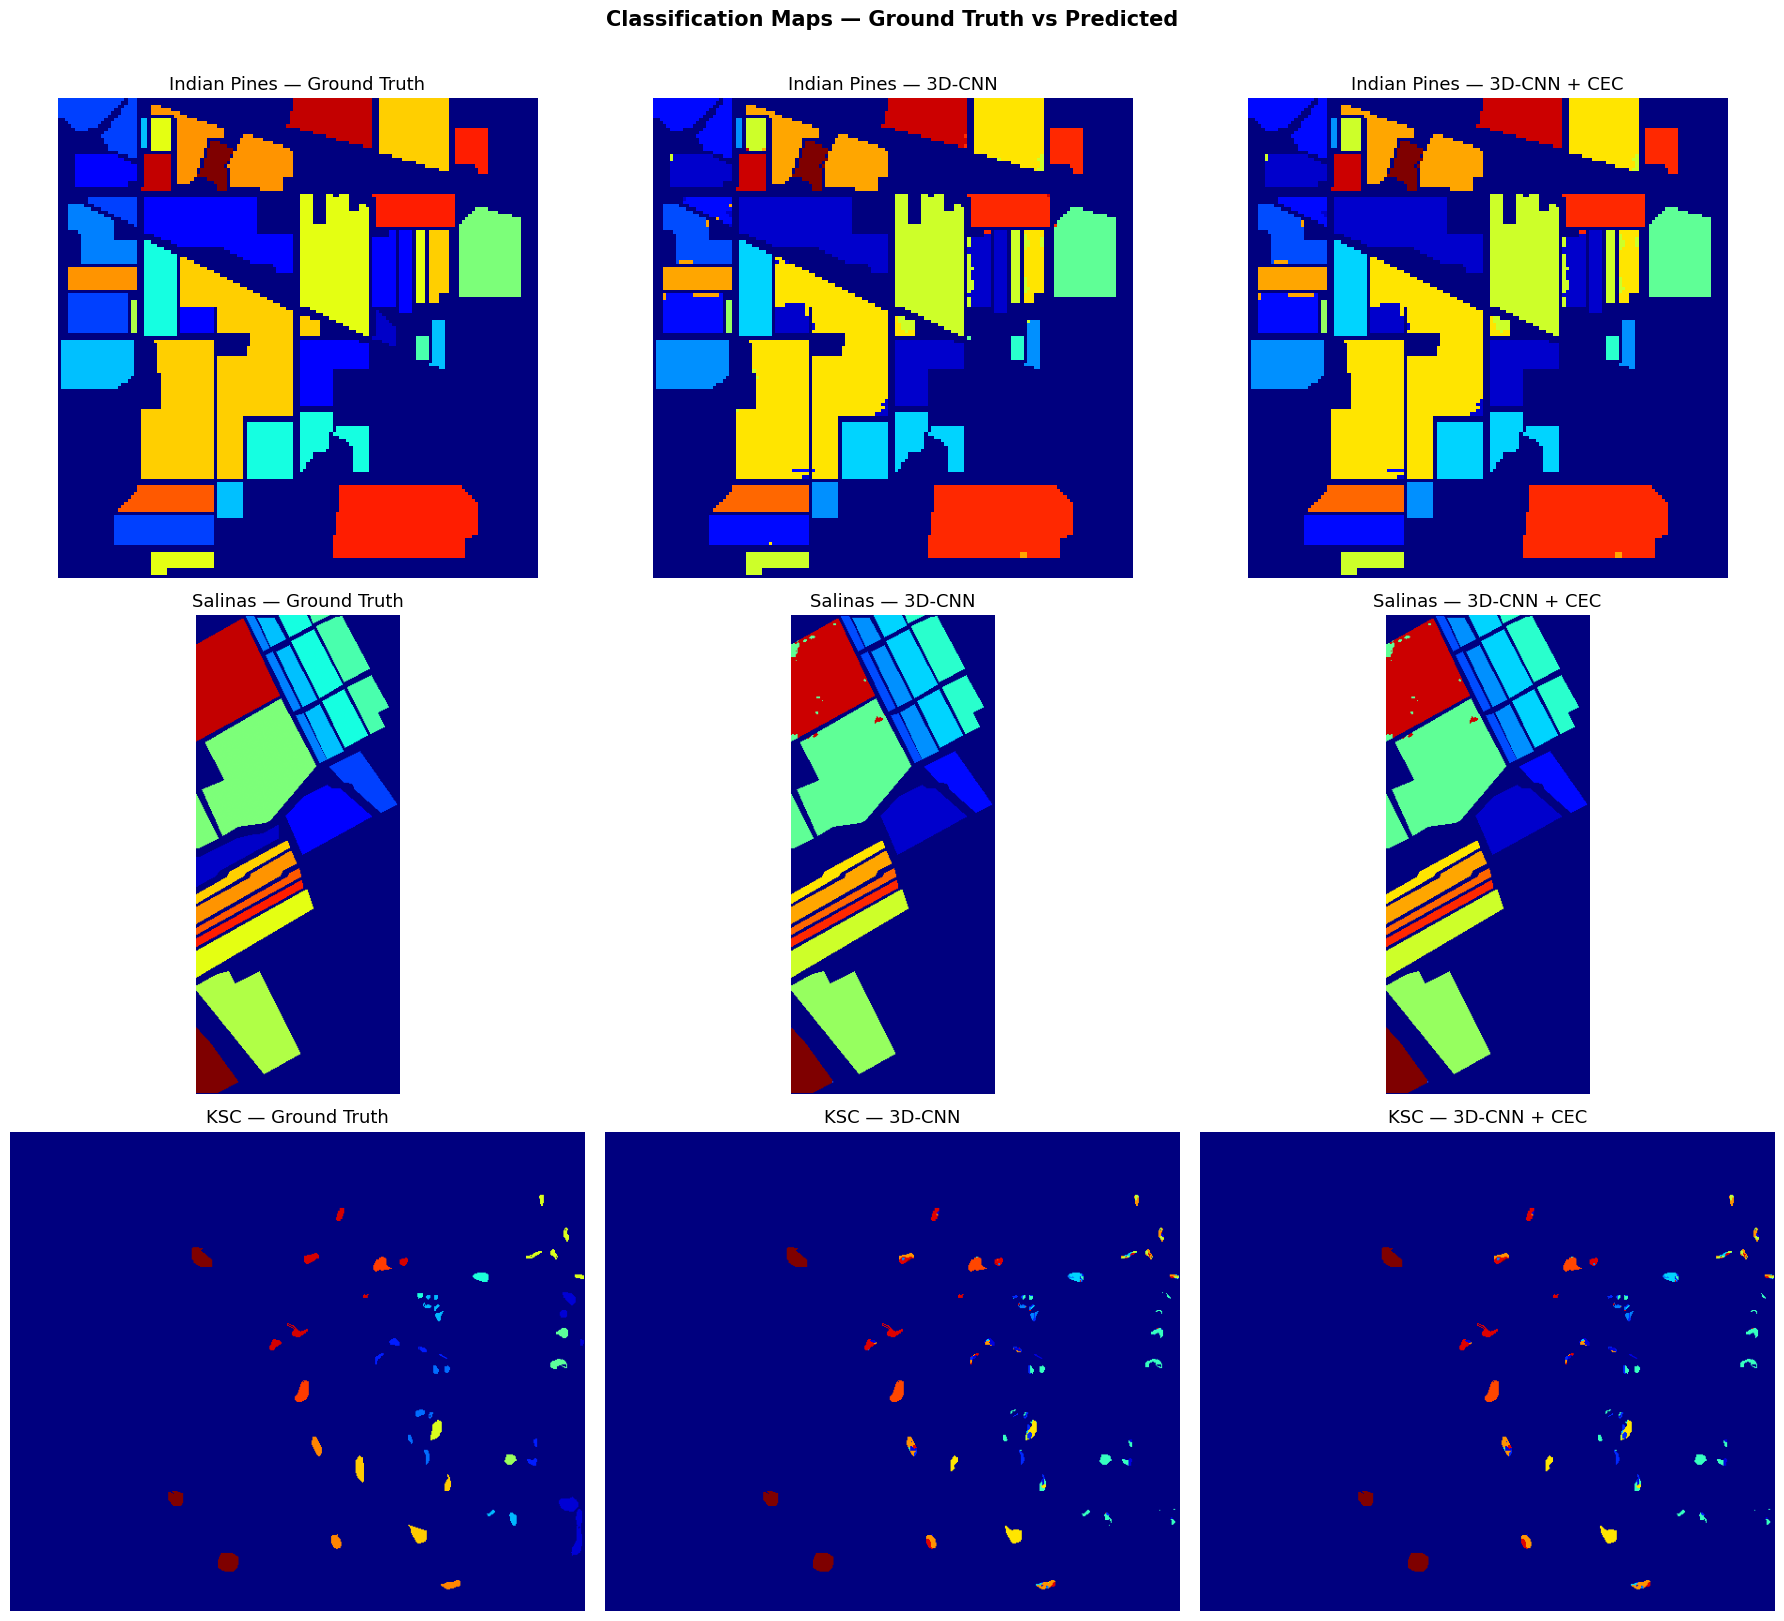

In [51]:
# ## 5.14 Visualization 1 — Classification Maps
#
# Ground Truth vs 3D-CNN vs 3D-CNN+CEC for all three datasets

fig, axes = plt.subplots(3, 3, figsize=(18, 16))

datasets = [
    ("Indian Pines", ip_labels,  ip_pred_map,  ip_corrected),
    ("Salinas",      sa_labels,  sa_pred_map,  sa_corrected),
    ("KSC",          ksc_labels, ksc_pred_map, ksc_corrected),
]

for row, (name, gt, pred, corr) in enumerate(datasets):
    axes[row, 0].imshow(gt,   cmap='jet')
    axes[row, 0].set_title(f'{name} — Ground Truth', fontsize=13)
    axes[row, 0].axis('off')

    axes[row, 1].imshow(pred, cmap='jet')
    axes[row, 1].set_title(f'{name} — 3D-CNN', fontsize=13)
    axes[row, 1].axis('off')

    axes[row, 2].imshow(corr, cmap='jet')
    axes[row, 2].set_title(f'{name} — 3D-CNN + CEC', fontsize=13)
    axes[row, 2].axis('off')

plt.suptitle('Classification Maps — Ground Truth vs Predicted',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('classification_maps.png', dpi=150, bbox_inches='tight')
plt.show()

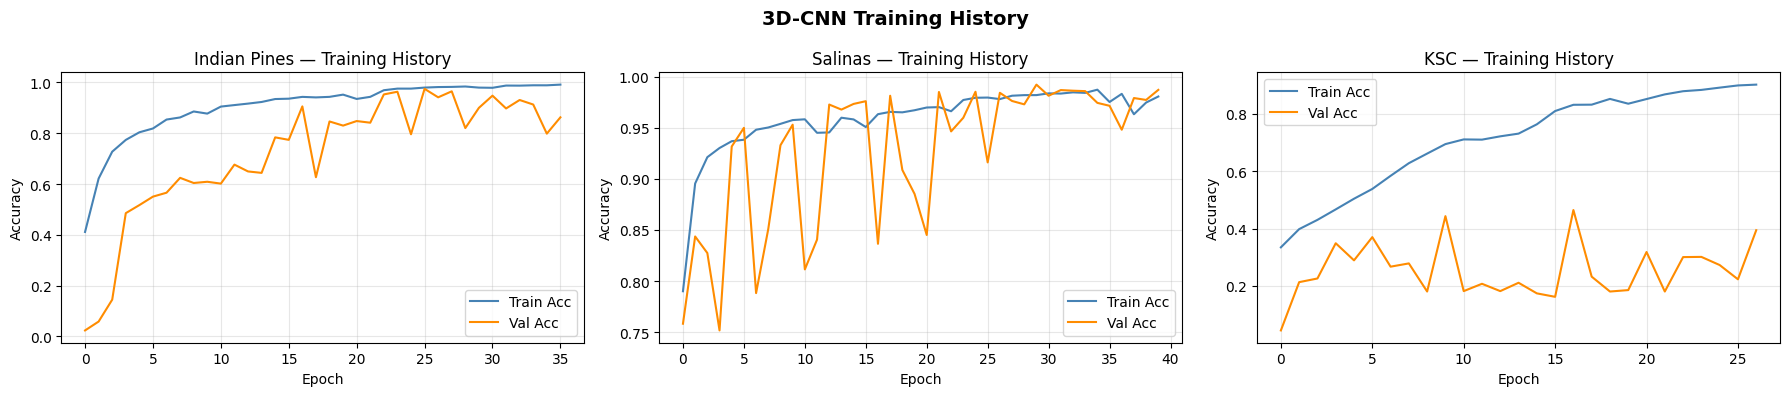

In [52]:
# ## 5.15 Visualization 2 — Training History

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, history, name in [
    (axes[0], ip_history,  'Indian Pines'),
    (axes[1], sa_history,  'Salinas'),
    (axes[2], ksc_history, 'KSC'),
]:
    ax.plot(history.history['accuracy'],
            label='Train Acc', color='steelblue')
    ax.plot(history.history['val_accuracy'],
            label='Val Acc',   color='darkorange')
    ax.set_title(f'{name} — Training History', fontsize=12)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('3D-CNN Training History', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('training_history.png', dpi=150, bbox_inches='tight')
plt.show()

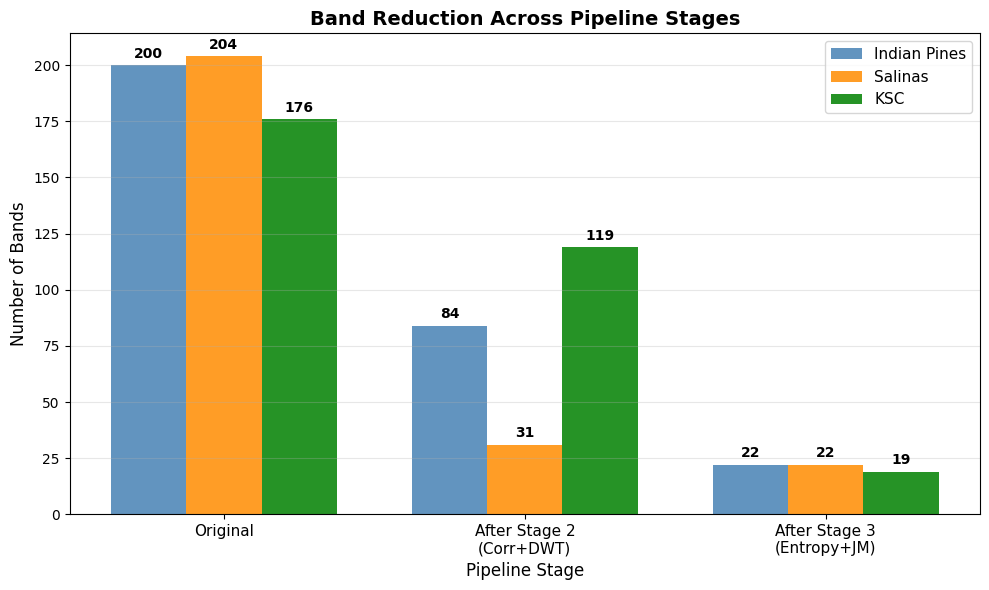

In [53]:
# ## 5.16 Visualization 3 — Band Reduction Chart
#
# Shows the progressive band reduction across all stages
# for each dataset — key figure for the paper.

datasets_info = {
    'Indian Pines': [200, 84, 22],
    'Salinas'     : [204, 31, 22],
    'KSC'         : [176, 119, 19],
}

stages = ['Original', 'After Stage 2\n(Corr+DWT)',
          'After Stage 3\n(Entropy+JM)']
x      = np.arange(len(stages))
width  = 0.25
colors = ['steelblue', 'darkorange', 'green']

fig, ax = plt.subplots(figsize=(10, 6))

for idx, (name, counts) in enumerate(datasets_info.items()):
    bars = ax.bar(x + idx * width, counts,
                  width, label=name, color=colors[idx], alpha=0.85)
    for bar, count in zip(bars, counts):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 2,
                str(count), ha='center', va='bottom',
                fontsize=10, fontweight='bold')

ax.set_xlabel('Pipeline Stage', fontsize=12)
ax.set_ylabel('Number of Bands', fontsize=12)
ax.set_title('Band Reduction Across Pipeline Stages',
             fontsize=14, fontweight='bold')
ax.set_xticks(x + width)
ax.set_xticklabels(stages, fontsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('band_reduction.png', dpi=150, bbox_inches='tight')
plt.show()

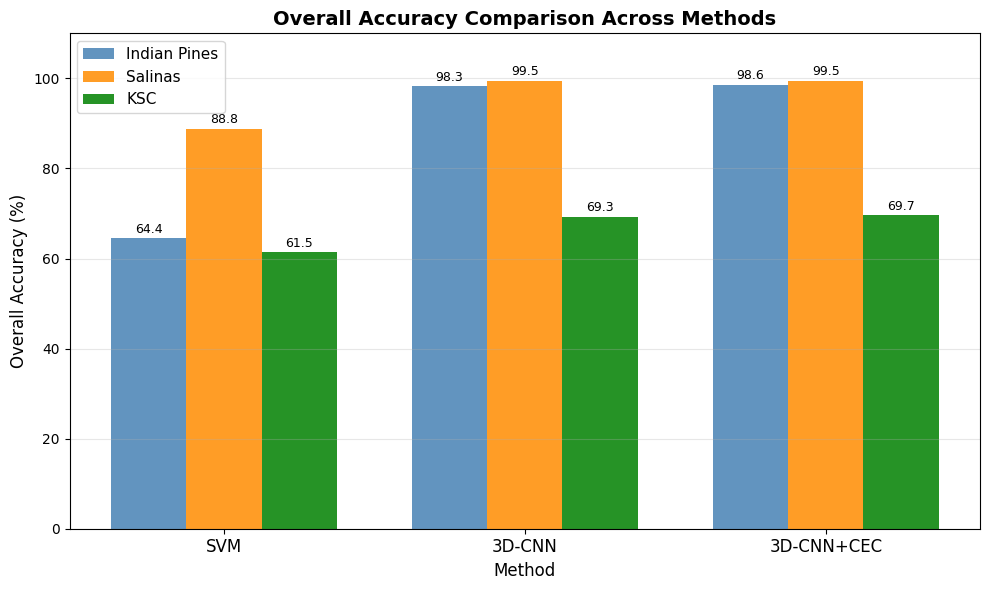

In [54]:
# ## 5.17 Visualization 4 — OA Comparison Bar Chart
#
# Side-by-side comparison of SVM vs 3D-CNN vs 3D-CNN+CEC
# for all three datasets.

methods  = ['SVM', '3D-CNN', '3D-CNN+CEC']
datasets_names = ['Indian Pines', 'Salinas', 'KSC']

ip_oas  = [ip_svm_m['OA'],  ip_map_m['OA'],  ip_cec_m['OA']]
sa_oas  = [sa_svm_m['OA'],  sa_map_m['OA'],  sa_cec_m['OA']]
ksc_oas = [ksc_svm_m['OA'], ksc_map_m['OA'], ksc_cec_m['OA']]

x     = np.arange(len(methods))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

b1 = ax.bar(x - width, ip_oas,  width, label='Indian Pines',
            color='steelblue', alpha=0.85)
b2 = ax.bar(x,         sa_oas,  width, label='Salinas',
            color='darkorange', alpha=0.85)
b3 = ax.bar(x + width, ksc_oas, width, label='KSC',
            color='green', alpha=0.85)

for bars in [b1, b2, b3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.5,
                f'{bar.get_height():.1f}',
                ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Method', fontsize=12)
ax.set_ylabel('Overall Accuracy (%)', fontsize=12)
ax.set_title('Overall Accuracy Comparison Across Methods',
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(methods, fontsize=12)
ax.set_ylim(0, 110)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('oa_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

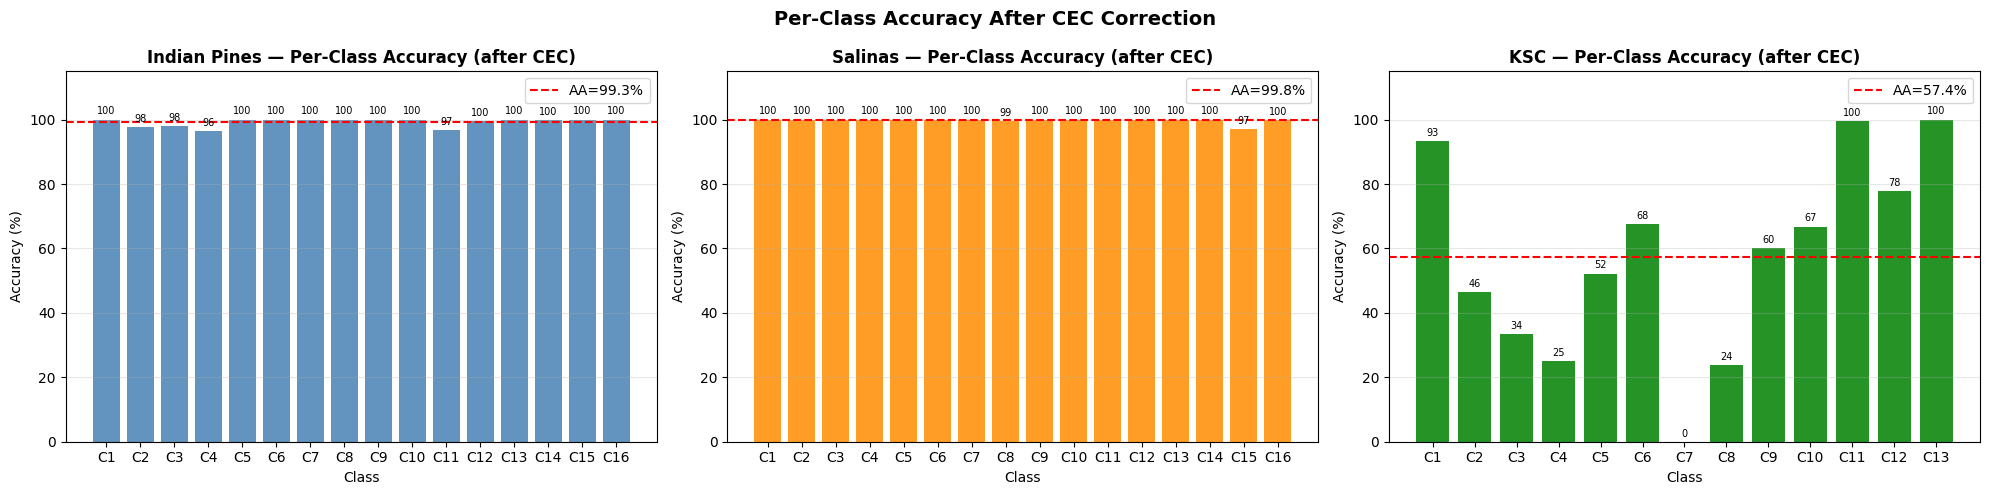

In [55]:
# ## 5.18 Visualization 5 — Per-Class Accuracy (ICA)
#
# Individual class accuracy after CEC for each dataset.
# Important for paper to show per-class performance.

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

ip_class_names = [f'C{i}' for i in range(1, 17)]
sa_class_names = [f'C{i}' for i in range(1, 17)]
ksc_class_names = [f'C{i}' for i in range(1, 14)]

for ax, name, metrics, class_names, color in [
    (axes[0], 'Indian Pines', ip_cec_m,  ip_class_names,  'steelblue'),
    (axes[1], 'Salinas',      sa_cec_m,  sa_class_names,  'darkorange'),
    (axes[2], 'KSC',          ksc_cec_m, ksc_class_names, 'green'),
]:
    bars = ax.bar(class_names, metrics['ICA'],
                  color=color, alpha=0.85)
    ax.axhline(metrics['AA'], color='red',
               linestyle='--', linewidth=1.5, label=f"AA={metrics['AA']:.1f}%")
    ax.set_title(f'{name} — Per-Class Accuracy (after CEC)',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Class')
    ax.set_ylabel('Accuracy (%)')
    ax.set_ylim(0, 115)
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 1,
                f'{bar.get_height():.0f}',
                ha='center', va='bottom', fontsize=7)

plt.suptitle('Per-Class Accuracy After CEC Correction',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('per_class_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

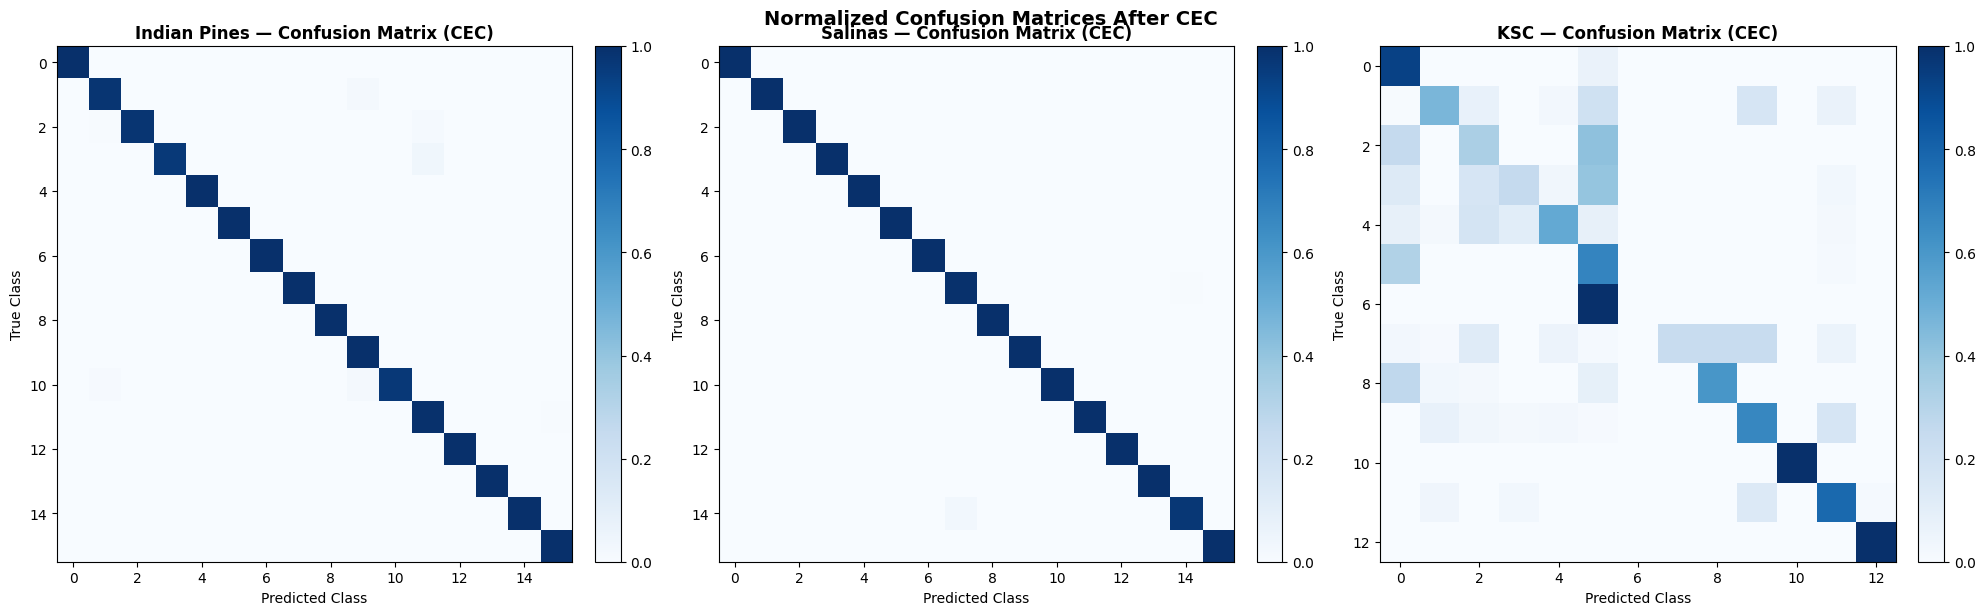

In [56]:
# ## 5.19 Visualization 6 — Confusion Matrix

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, name, y_true, y_pred, n_cls in [
    (axes[0], 'Indian Pines', ip_ytest_enc,
     ip_corrected[rows_ip,   cols_ip],  16),
    (axes[1], 'Salinas',      sa_ytest_enc,
     sa_corrected[rows_sa,   cols_sa],  16),
    (axes[2], 'KSC',          ksc_ytest_enc,
     ksc_corrected[rows_ksc, cols_ksc], 13),
]:
    cm = confusion_matrix(y_true, y_pred)
    # Normalize
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
    ax.set_title(f'{name} — Confusion Matrix (CEC)',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Class')
    ax.set_ylabel('True Class')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('Normalized Confusion Matrices After CEC',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

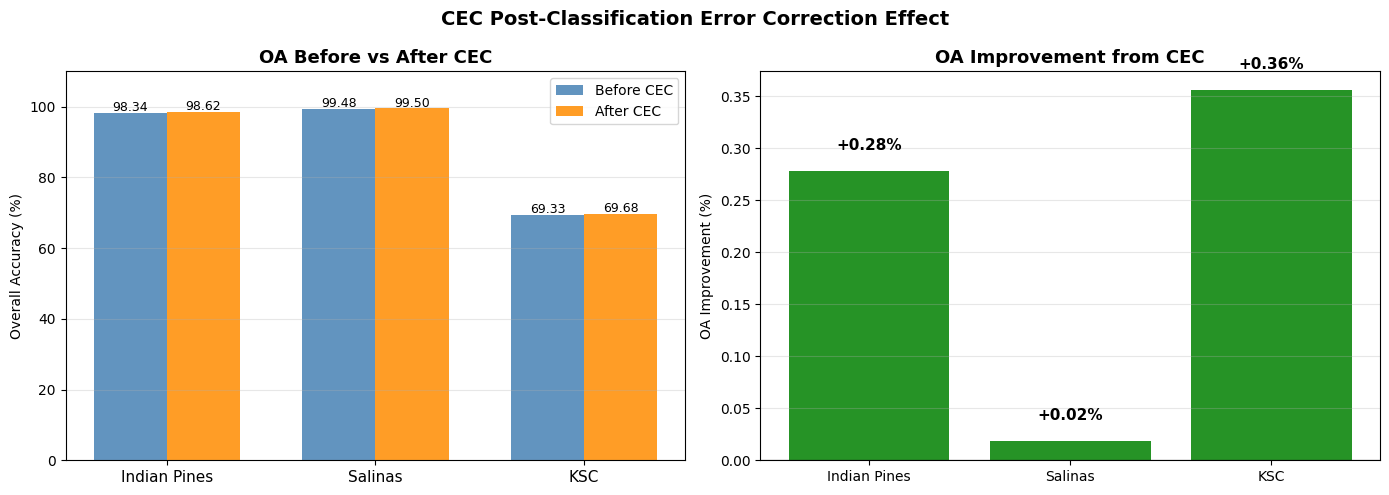

In [57]:
# ## 5.20 Visualization 7 — CEC Improvement Chart

datasets_names = ['Indian Pines', 'Salinas', 'KSC']
before_oa = [ip_map_m['OA'],  sa_map_m['OA'],  ksc_map_m['OA']]
after_oa  = [ip_cec_m['OA'],  sa_cec_m['OA'],  ksc_cec_m['OA']]
improvement = [a - b for a, b in zip(after_oa, before_oa)]

x     = np.arange(len(datasets_names))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left — before vs after
axes[0].bar(x - width/2, before_oa, width,
            label='Before CEC', color='steelblue', alpha=0.85)
axes[0].bar(x + width/2, after_oa,  width,
            label='After CEC',  color='darkorange', alpha=0.85)
axes[0].set_title('OA Before vs After CEC',
                  fontsize=13, fontweight='bold')
axes[0].set_ylabel('Overall Accuracy (%)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(datasets_names, fontsize=11)
axes[0].set_ylim(0, 110)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)
for i, (b, a) in enumerate(zip(before_oa, after_oa)):
    axes[0].text(i - width/2, b + 0.5, f'{b:.2f}',
                 ha='center', fontsize=9)
    axes[0].text(i + width/2, a + 0.5, f'{a:.2f}',
                 ha='center', fontsize=9)

# Right — improvement
colors_imp = ['green' if v > 0 else 'red' for v in improvement]
axes[1].bar(datasets_names, improvement,
            color=colors_imp, alpha=0.85)
axes[1].set_title('OA Improvement from CEC',
                  fontsize=13, fontweight='bold')
axes[1].set_ylabel('OA Improvement (%)')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].grid(axis='y', alpha=0.3)
for i, v in enumerate(improvement):
    axes[1].text(i, v + 0.02, f'+{v:.2f}%',
                 ha='center', fontsize=11, fontweight='bold')

plt.suptitle('CEC Post-Classification Error Correction Effect',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('cec_improvement.png', dpi=150, bbox_inches='tight')
plt.show()

In [58]:
# ## 5.21 Save All Results and Models

# Save classification maps
np.save('ip_pred_map.npy',   ip_pred_map)
np.save('sa_pred_map.npy',   sa_pred_map)
np.save('ksc_pred_map.npy',  ksc_pred_map)

np.save('ip_corrected.npy',  ip_corrected)
np.save('sa_corrected.npy',  sa_corrected)
np.save('ksc_corrected.npy', ksc_corrected)

# Save models
ip_model.save('ip_model_final.keras')
sa_model.save('sa_model_final.keras')
ksc_model.save('ksc_model_final.keras')

print("All results and models saved")
print("\n" + "=" * 50)
print("Pipeline Complete")
print("=" * 50)
print(f"\nFinal OA Results:")
print(f"  Indian Pines  3D-CNN+CEC : {ip_cec_m['OA']:.2f}%")
print(f"  Salinas       3D-CNN+CEC : {sa_cec_m['OA']:.2f}%")
print(f"  KSC           3D-CNN+CEC : {ksc_cec_m['OA']:.2f}%")
print(f"\nSaved visualizations:")
print(f"  classification_maps.png")
print(f"  training_history.png")
print(f"  band_reduction.png")
print(f"  oa_comparison.png")
print(f"  per_class_accuracy.png")
print(f"  confusion_matrices.png")
print(f"  cec_improvement.png")

All results and models saved

Pipeline Complete

Final OA Results:
  Indian Pines  3D-CNN+CEC : 98.62%
  Salinas       3D-CNN+CEC : 99.50%
  KSC           3D-CNN+CEC : 69.68%

Saved visualizations:
  classification_maps.png
  training_history.png
  band_reduction.png
  oa_comparison.png
  per_class_accuracy.png
  confusion_matrices.png
  cec_improvement.png
